# ==========================================================
# NOTEBOOK 03
# Mixed Models, Variance Components and BLUP Estimation
# ==========================================================

## Objectives

Following data integration, quality control and exploratory analyses (Notebook 02), this notebook estimates the true genetic performance of potato genotypes using linear mixed models.

Specifically, this notebook will:

- Estimate variance components for important agronomic traits.
- Quantify broad-sense heritability.
- Predict Best Linear Unbiased Predictors (BLUPs) for breeding clones.
- Estimate Best Linear Unbiased Estimates (BLUEs) for commercial checks.
- Evaluate model assumptions.
- Generate publication-quality tables and figures.
- Produce outputs for Multi-Environment Trial (MET) analyses in Notebook 04.

The analyses performed here form the quantitative genetics foundation for genotype evaluation and selection within the potato breeding program.

In [ ]:
# ==========================================================
# Mounting Google Drive
# ==========================================================

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ==========================================================
# Import Libraries
# ==========================================================

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

import statsmodels.api as sm
import statsmodels.formula.api as smf

from statsmodels.graphics.gofplots import qqplot

# ----------------------------------------------------------
# Plot settings
# ----------------------------------------------------------

plt.style.use("ggplot")

plt.rcParams.update({
    "figure.figsize": (10,6),
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12
})

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("="*70)
print("NOTEBOOK 03: MIXED MODELS AND BLUP ESTIMATION")
print("="*70)

NOTEBOOK 03: MIXED MODELS AND BLUP ESTIMATION



The required libraries were imported successfully. These packages provide functionality for data manipulation, statistical modelling, graphical visualization and mixed model analyses. Plotting parameters were standardized to ensure publication-quality graphics throughout the notebook.

In [129]:
# ==========================================================
# Project directories
# ==========================================================

PROJECT_DIR = Path("/content/drive/MyDrive/Potato_CET_Project")

DATA_DIR = PROJECT_DIR / "data"

RAW_DIR = DATA_DIR / "raw"

PROCESSED_DIR = DATA_DIR / "processed"

OUTPUT_DIR = PROJECT_DIR / "outputs"

FIGURES_DIR = OUTPUT_DIR / "figures"
TABLES_DIR = OUTPUT_DIR / "tables"
MODELS_DIR = OUTPUT_DIR / "models"

for folder in [OUTPUT_DIR,
               FIGURES_DIR,
               TABLES_DIR,
               MODELS_DIR]:
    folder.mkdir(exist_ok=True)

TABLES_DIR_STR = str(TABLES_DIR) # Convert Path object to string for R
OUTPUT_DIR_STR = str(OUTPUT_DIR) # Convert Path object to string for R

print("Project directories verified.")

Project directories verified.



A standardized directory structure was established to ensure reproducibility and facilitate automatic storage of all figures, tables and model outputs generated during the analyses.

# SECTION 1 — Load and Verify the Clean Dataset

This section may look simple, but it's critical. Before fitting any mixed model, we must confirm that the cleaned dataset from Notebook 02 is complete, correctly formatted, and ready for analysis.

In [ ]:
# ==========================================================
# Check files in the processed directory
# ==========================================================

print(PROCESSED_DIR)

print("\nFiles in processed folder:\n")

for file in PROCESSED_DIR.iterdir():
    print(file.name)

/content/drive/MyDrive/Potato_CET_Project/data/processed

Files in processed folder:

analysis_ready.csv
analysis_ready_EA21.csv
analysis_ready_LBHT.csv
master_raw.csv


In [ ]:
# ==========================================================
# Load analysis-ready dataset
# ==========================================================

DATA_FILE = PROCESSED_DIR / "analysis_ready.csv"

master = pd.read_csv(DATA_FILE)

print("="*70)
print("ANALYSIS-READY PHENOTYPIC DATASET")
print("="*70)

print(f"Rows      : {master.shape[0]:,}")
print(f"Columns   : {master.shape[1]}")

master.head()

ANALYSIS-READY PHENOTYPIC DATASET
Rows      : 1,320
Columns   : 119


,plot,geno,entry,row,column,rep,ntp,npe,growth_speed,pgh,plant_unif,plant_vigor,flowering,flowering_date,flower_colour,overall_impression,se,tuber_apper,tub_unif,tub_size,skin_colour,flesh_colour,late_blight_60_days,late_blight_90_days,notes,notes2,selected_clone,name,comment,0_10,0_10_1,weight_g_0_10,weight_0_10,average_length_mm_0_10,10_30,10_30_1,weight_g_10_30,weight_10_30,average_length_mm_10_30,average_length_mm_10,30_35,30_35_1,weight_g_30_35,weight_30_35,average_length_mm_30_35,average_length_mm_30,35_40,35_40_1,weight_g_35_40,weight_35_40,average_length_mm_35_40,average_length_mm_35,40_45,40_45_1,weight_g_40_45,weight_40_45,average_length_mm_40_45,average_length_mm_40,45_50,45_50_1,weight_g_45_50,weight_45_50,average_length_mm_45_50,average_length_mm_45,50_55,50_55_1,weight_g_50_55,weight_50_55,average_length_mm_50_55,average_length_mm_50,55_60,55_60_1,weight_g_55_60,weight_55_60,average_length_mm_55_60,average_length_mm_55,60_65,60_65_1,weight_g_60_65,weight_60_65,average_length_mm_60_65,average_length_mm_60,65_70,65_70_1,weight_g_65_70,weight_65_70,average_length_mm_65_70,average_length_mm_65,70,70_1,weight_g_70,weight_70,average_length_mm_70,total,weight_g_total,owg_g_total,owg_g_5kg_total,average_length_mm_total,average_nir_value_total,trial,location,population,total_weight_in_kgs,weight_in_air_kgs,weight_in_water_kgs,dm,late_blight_50_days,notes_1,photo_1,wilted,rotten_tubers,selected_and_non_selected,nph,late_blight_70_days,late_blight_80_days,photo,selected,tubers_shape,selected_clones
0,NaN,CIP3217004.022,10,1,1,1,20.0,20,5.0,2.0,7.0,9.0,3.0,2025-07-18 00:00:00,Purple,8.0,7.0,7.0,7.0,7.0,Light red,creme,NaN,5.0,NaN,"red eyes, nice tubers,",Selected,1.0,1.0,0.0,0.0,0.0,0.0,NaN,11.0,5.7,120.2,0.6,33.3,75.8,15.0,7.8,396.3,1.9,46.4,78.4,12.0,6.2,498.4,2.4,54.4,81.3,24.0,12.4,1458.3,7.1,63.7,83.4,28.0,14.5,2365.6,11.6,71.1,87.0,48.0,24.9,5694.9,27.9,85.5,91.3,32.0,16.6,5096.9,25.0,93.4,96.3,18.0,9.3,3658.1,17.9,100.8,100.3,5.0,2.6,1135.4,5.6,98.6,98.6,0.0,0.0,0.0,0.0,NaN,193.0,20423.7,0.0,0.0,75.8,148.7,KE25MOL-EA21-AT01_table-Final,Molo,EA21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,CIP3177023.046,3,2,1,1,20.0,7,3.0,2.0,5.0,3.0,3.0,2024-07-22 00:00:00,White,4.0,3.0,5.0,7.0,5.0,Yellow,yellow,0.0,0.0,small plants,few tubers,Not Selected,2.0,2.0,0.0,0.0,0.0,0.0,NaN,2.0,14.3,20.8,2.8,31.0,57.6,1.0,7.1,17.6,2.3,38.8,62.1,0.0,0.0,0.0,0.0,NaN,64.2,4.0,28.6,202.1,26.8,56.3,64.2,7.0,50.0,513.4,68.1,68.7,68.7,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,NaN,14.0,753.9,0.0,0.0,57.6,145.7,KE25MOL-EA21-AT01_table-Final,Molo,EA21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,CIP3217016.038,47,3,1,1,20.0,15,5.0,2.0,5.0,5.0,0.0,NaN,NaN,5.0,5.0,7.0,5.0,7.0,Red,yellow,0.0,0.0,NaN,"few tubers, unica like",Not Selected,3.0,3.0,0.0,0.0,0.0,0.0,NaN,5.0,9.6,49.8,1.0,32.4,77.5,5.0,9.6,117.1,2.3,45.1,82.3,5.0,9.6,198.1,3.8,56.0,86.7,8.0,15.4,465.3,9.0,65.6,90.9,10.0,19.2,925.7,17.9,80.4,97.9,8.0,15.4,1021.7,19.8,98.9,107.1,4.0,7.7,681.1,13.2,108.6,113.0,3.0,5.8,618.8,12.0,106.6,115.5,4.0,7.7,1093.5,21.1,122.2,122.2,0.0,0.0,0.0,0.0,NaN,52.0,5171.8,0.0,0.0,77.5,148.7,KE25MOL-EA21-AT01_table-Final,Molo,EA21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,CIP3217016.076,48,4,1,1,20.0,17,5.0,2.0,7.0,7.0,5.0,2024-07-08 00:00:00,White,6.0,5.0,5.0,5.0,5.0,Yellow,light yellow,10.0,70.0,NaN,long oval tubers,Not Selected,4.0,4.0,0.0,0.0,0.0,0.0,NaN,11.0,15.9,170.6,3.6,43.9,76.6,12.0,17.4,384.6,8.0,57.7,82.8,15.0,21.7,903.2,18.9,77.5,89.4,14.0,20.3,1127.6,23.5,84.8,95.1,10.0,14.5,1080.9,22.6,98.7,103.6,6.0,8.7,917.2,19.2,109.3,110.6,1.0,1.4,205.0,4.3,118.8,118.8,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,NaN,69.0,4789.0,0.0,0.0,76.6,153.4,KE25MOL-EA21-AT01_table-Final,Molo,EA21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,CIP3217006.008,20,5,1,1,20.0,

In [ ]:
# ==========================================================
# Data structure
# ==========================================================

print("="*70)
print("DATA STRUCTURE")
print("="*70)

master.info()

DATA STRUCTURE
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1320 entries, 0 to 1319
Columns: 119 entries, plot to selected_clones
dtypes: float64(97), int64(5), object(17)
memory usage: 1.2+ MB


In [ ]:
# ==========================================================
# Verify key variables
# ==========================================================

key_variables = [
    "trial",
    "geno",
    "rep",
    "row",
    "column",
    "weight_g_total"
]

verification = pd.DataFrame({
    "Variable": key_variables,
    "Present": [col in master.columns for col in key_variables],
    "Missing Values": [
        master[col].isna().sum() if col in master.columns else np.nan
        for col in key_variables
    ],
    "Data Type": [
        master[col].dtype if col in master.columns else ""
        for col in key_variables
    ]
})

verification

,Variable,Present,Missing Values,Data Type
0,trial,True,0,object
1,geno,True,0,object
2,rep,True,0,int64
3,row,True,0,int64
4,column,True,0,int64
5,weight_g_total,True,189,float64


In [ ]:
# ==========================================================
# Experimental design overview
# ==========================================================

summary = pd.DataFrame({
    "Statistic": [
        "Trials",
        "Genotypes",
        "Replications",
        "Rows",
        "Columns",
        "Yield observations"
    ],
    "Value": [
        master["trial"].nunique(),
        master["geno"].nunique(),
        master["rep"].nunique(),
        master["row"].nunique(),
        master["column"].nunique(),
        master["weight_g_total"].notna().sum()
    ]
})

summary

,Statistic,Value
0,Trials,6
1,Genotypes,191
2,Replications,1
3,Rows,44
4,Columns,11
5,Yield observations,1131


## Loading the Analysis-Ready Dataset

The analysis-ready phenotypic dataset comprised **1,320 experimental plots** evaluated across **six multi-environment trials** conducted during the 2025 growing season.

After quality control (Notebook 02), the dataset contained **191 unique potato genotypes**, including elite breeding clones and commercial check varieties, evaluated under two breeding populations (EA21 and LBHT).

The dataset contained **119 variables**, representing field design information, agronomic observations, disease scores, tuber size distributions, marketable yield, dry matter traits, and environmental identifiers.

Among the 1,320 plots, **1,131 observations contained recorded total tuber yield**, while **189 observations were missing yield measurements**, primarily resulting from failed harvests, missing plants, or plots intentionally retained as placeholders within the experimental design.

The six trials represent distinct combinations of testing location and breeding population:

- Molo EA21
- Molo LBHT
- Njoro EA21
- Njoro LBHT
- University of Nairobi (UoN) EA21
- University of Nairobi (UoN) LBHT

These environments provide substantial environmental diversity for estimating genotype performance and genotype × environment interaction in subsequent mixed-model analyses.

Overall, the dataset provides a robust foundation for estimating genetic parameters, predicting genotype performance using Best Linear Unbiased Predictors (BLUPs), and evaluating genotype stability across contrasting highland environments.

## Experimental Design

The analysis-ready dataset comprised **1,320 field plots** evaluated across **six multi-environment trials**. The experiments were established using a **partially replicated (p-rep) design**, in which the majority of elite breeding clones were evaluated in a single plot, while commercial check varieties were intentionally replicated throughout the field to improve estimation of experimental error and field heterogeneity.

The dataset contained:

- **191 potato genotypes**
- **6 trial environments**
- **1 nominal field replication (p-rep design)**
- **1,131 plots with recorded tuber yield**

The p-rep design is particularly suitable for breeding programs because it maximizes the number of breeding lines evaluated while maintaining sufficient precision through replicated checks. Consequently, subsequent analyses will employ mixed-model methodology, where genotype effects are predicted using Best Linear Unbiased Predictors (BLUPs) while accounting for the partially replicated experimental structure.

# Section 2 — Trait Missingness Assessment

Although Notebook 02 summarized missing yield values, before fitting mixed models we need to know the amount of data available for each trait. Different analyses will use different traits, and this determines the effective sample size.

In [ ]:
# ==========================================================
# Trait completeness
# ==========================================================

traits = [
    "weight_g_total",
    "dm",
    "late_blight_60_days",
    "late_blight_90_days",
    "nph",
    "ntp"
]

missing_summary = (
    master[traits]
    .isna()
    .agg(["sum", "count"])
    .T
    .rename(columns={"sum": "Missing", "count": "Total"})
)

missing_summary["Available"] = (
    missing_summary["Total"] -
    missing_summary["Missing"]
)

missing_summary["Percent Missing"] = (
    100 *
    missing_summary["Missing"] /
    missing_summary["Total"]
).round(2)

missing_summary = missing_summary[
    ["Available", "Missing", "Percent Missing"]
]

display(missing_summary)

,Available,Missing,Percent Missing
weight_g_total,1131,189,14.32
dm,172,1148,86.97
late_blight_60_days,699,621,47.05
late_blight_90_days,1063,257,19.47
nph,368,952,72.12
ntp,1056,264,20.00


<Figure size 1200x600 with 0 Axes>

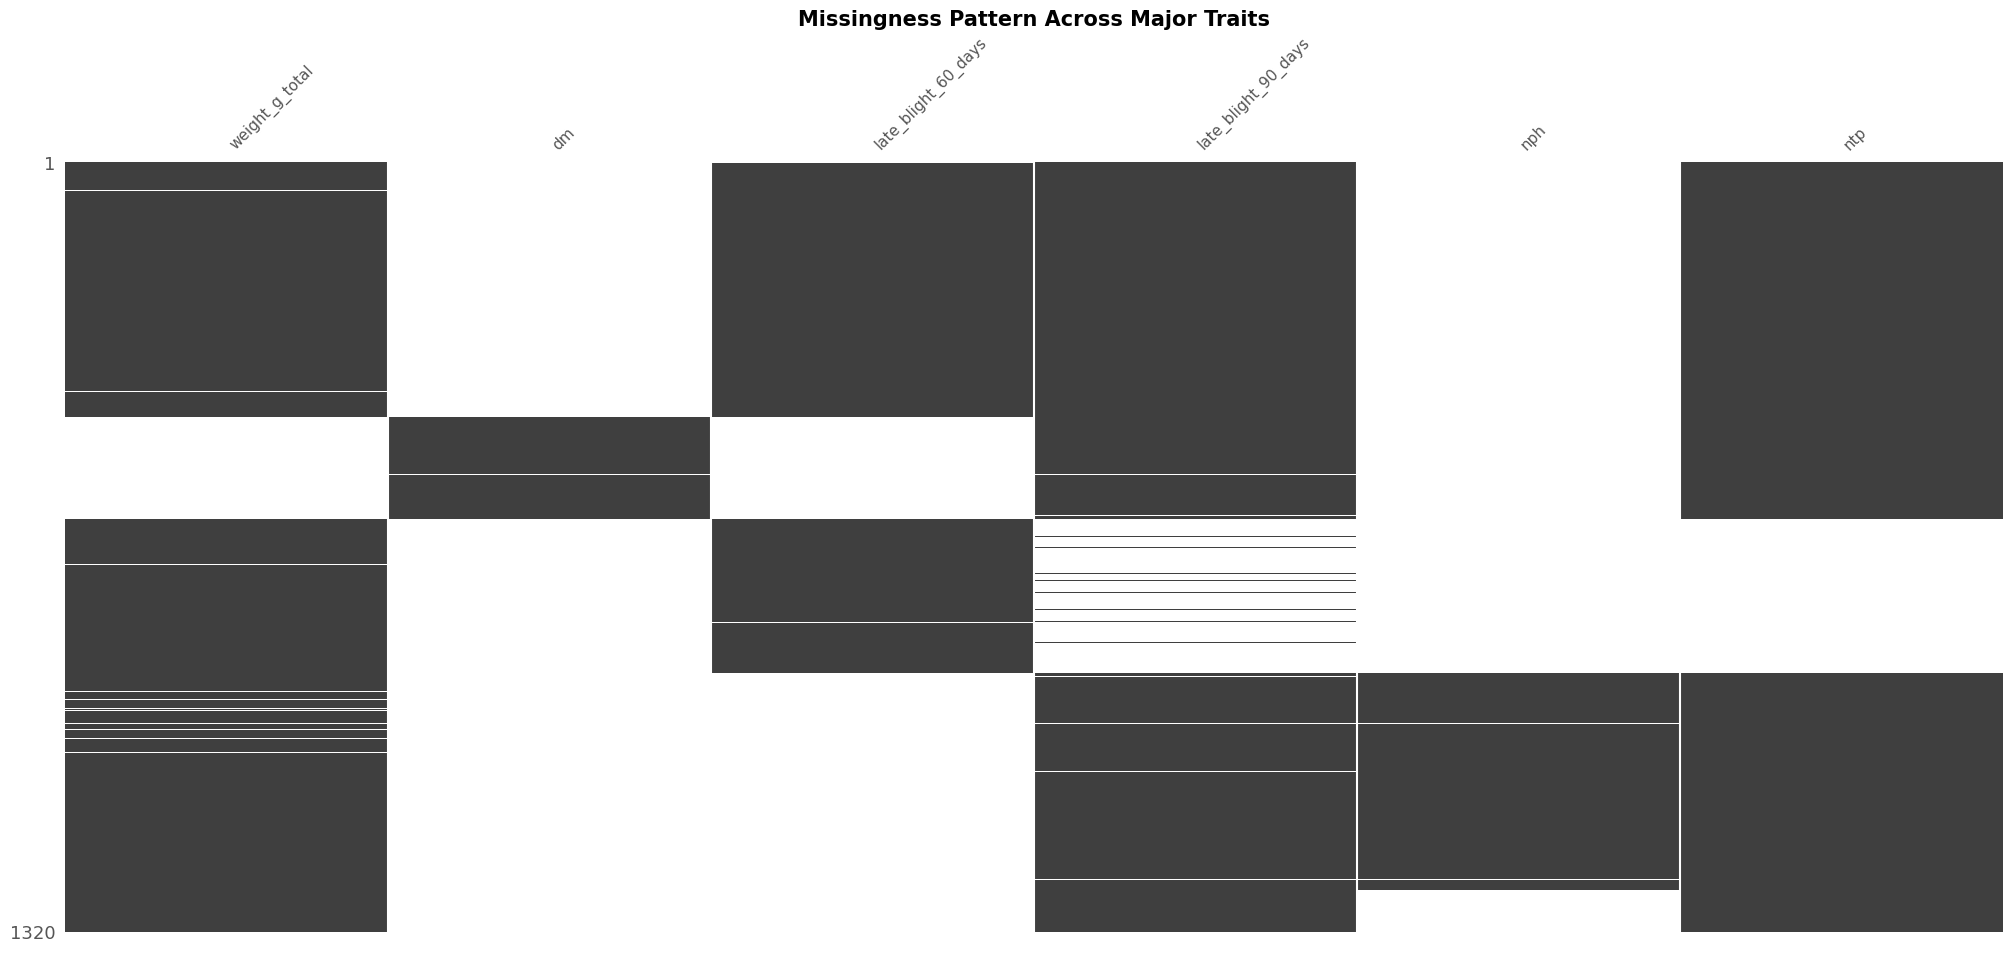

In [ ]:
import matplotlib.pyplot as plt
import missingno as msno

plt.figure(figsize=(12,6))

msno.matrix(
    master[traits],
    fontsize=11,
    sparkline=False
)

plt.title(
    "Missingness Pattern Across Major Traits",
    fontsize=15,
    weight="bold"
)

plt.show()

## Interpretation
Missingness assessment of major traits

The missing data assessment revealed substantial differences in data completeness across the measured traits (Figure X).

Total tuber yield (weight_g_total), the primary response variable for subsequent mixed-model analyses, exhibited 14.3% missing observations, leaving 1,131 valid yield records available for analysis. This level of missingness is acceptable for mixed-model analyses because REML estimation is specifically designed to accommodate unbalanced datasets.

Late blight severity at 90 days showed relatively high completeness, with 80.5% of observations available, whereas late blight at 60 days contained approximately 47% missing values. The reduced completeness of early disease scores likely reflects differences in disease development among environments or incomplete disease assessments during field evaluations.

Dry matter content was available for only 172 observations (13%), indicating that this trait was measured on a subset of genotypes rather than across the entire experimental population. Likewise, the number of plants harvested (nph) was recorded for only 27.9% of plots, suggesting that this variable served primarily as an auxiliary management measurement rather than a routine breeding trait.

The number of tubers per plot (ntp) contained 20% missing values, providing adequate data for exploratory analyses but requiring careful consideration in downstream modeling.

Importantly, the observed missingness follows the expected structure of operational breeding trials rather than random data loss. Traits such as dry matter and disease scores are commonly measured only in selected environments or subsets of breeding materials because of labor, cost, or experimental priorities. Consequently, no evidence suggests systematic errors during data processing.

Overall, the missing data pattern confirms that the dataset is suitable for mixed-model analysis using REML, which naturally accommodates the incomplete and unbalanced data structures typical of partially replicated potato breeding trials.

# **Section 3.2 Experimental Design Diagnostics**

Is the experimental design suitable for mixed-model analysis?

In [ ]:
# ==========================================================
# SECTION 3.2
# Experimental Design Diagnostics
# ==========================================================

import pandas as pd

print("="*70)
print("EXPERIMENTAL DESIGN SUMMARY")
print("="*70)

summary = pd.DataFrame({

    "Metric":[
        "Total observations",
        "Genotypes",
        "Environments",
        "Rows",
        "Columns",
        "Replications",
    ],

    "Value":[
        len(master),
        master["geno"].nunique(),
        master["trial"].nunique(),
        master["row"].nunique(),
        master["column"].nunique(),
        master["rep"].nunique()
    ]
})

display(summary)

EXPERIMENTAL DESIGN SUMMARY


,Metric,Value
0,Total observations,1320
1,Genotypes,191
2,Environments,6
3,Rows,44
4,Columns,11
5,Replications,1


In [ ]:
# ==========================================================
# Number of plots per environment
# ==========================================================

env_summary = (
    master
    .groupby(["trial","location","population"])
    .size()
    .reset_index(name="Plots")
    .sort_values("Plots",ascending=False)
)

display(env_summary)

,trial,location,population,Plots
1,KE25MOL-LBHT-IT01_table-Final,Molo,LBHT,264
3,KE25NJO-LBHT-IT01_table-Final,Njoro,LBHT,264
5,KE25UON-LBHT-IT01_table-Final,Nairobi,LBHT,264
4,KE25UON-EA21-AT01_table-Final,Nairobi,EA21,180
0,KE25MOL-EA21-AT01_table-Final,Molo,EA21,174
2,KE25NJO-EA21-AT01_table-Final,Njoro,EA21,174


In [ ]:
# ==========================================================
# Genotype connectivity
# ==========================================================

geno_env = (
    master
    .groupby("geno")["trial"]
    .nunique()
    .value_counts()
    .sort_index()
    .rename_axis("Number of environments")
    .reset_index(name="Genotypes")
)

display(geno_env)

,Number of environments,Genotypes
0,1,20
1,2,20
2,3,147
3,6,4


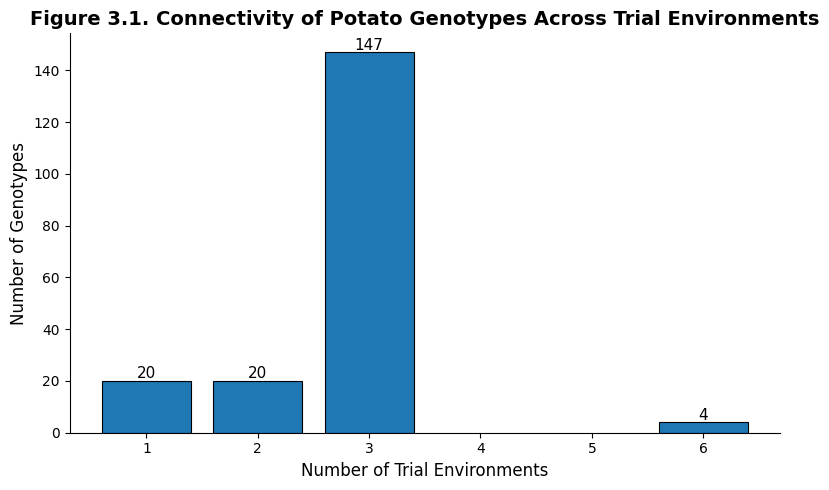

In [ ]:
# ==========================================================
# Publication Figure
# Genotype connectivity
# ==========================================================

import matplotlib.pyplot as plt

plt.style.use("default")

fig, ax = plt.subplots(figsize=(8,5))

bars = ax.bar(
    geno_env["Number of environments"],
    geno_env["Genotypes"],
    edgecolor="black",
    linewidth=0.8
)

for b in bars:
    ax.text(
        b.get_x()+b.get_width()/2,
        b.get_height()+1,
        int(b.get_height()),
        ha="center",
        fontsize=11
    )

ax.set_xlabel("Number of Trial Environments",fontsize=12)
ax.set_ylabel("Number of Genotypes",fontsize=12)

ax.set_title(
    "Figure 3.1. Connectivity of Potato Genotypes Across Trial Environments",
    fontsize=14,
    fontweight="bold"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR/"Figure_3_1_Genotype_Connectivity.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

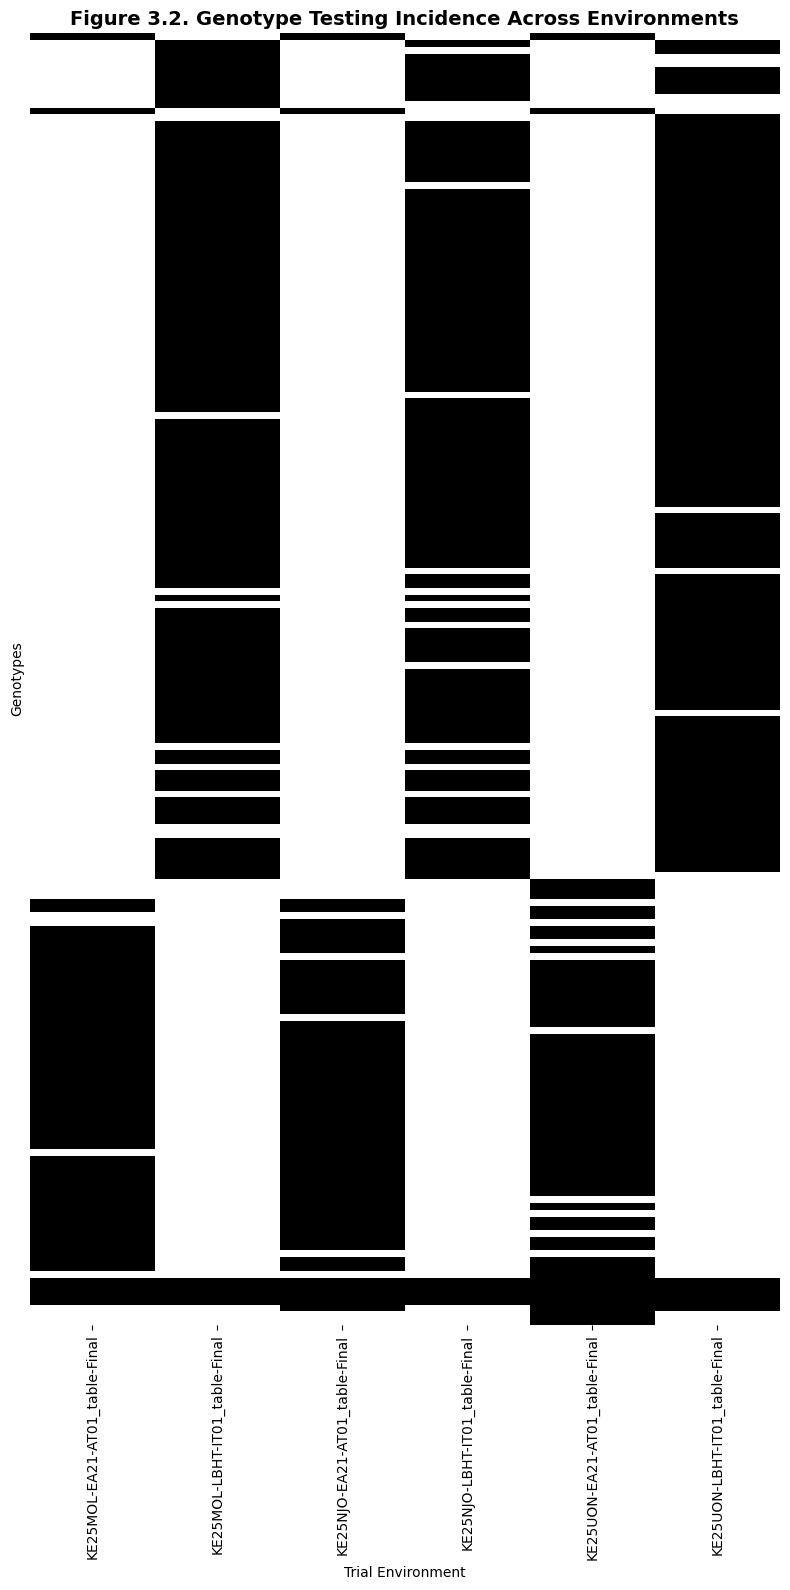

In [ ]:
# ==========================================================
# Genotype × Environment incidence matrix
# ==========================================================

import seaborn as sns

incidence = pd.crosstab(
    master["geno"],
    master["trial"]
)

incidence = (incidence>0).astype(int)

plt.figure(figsize=(8,16))

sns.heatmap(
    incidence,
    cmap="Greys",
    cbar=False,
    yticklabels=False,
    linewidths=0
)

plt.title(
    "Figure 3.2. Genotype Testing Incidence Across Environments",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Trial Environment")
plt.ylabel("Genotypes")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR/"Figure_3_2_GxE_Incidence.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ==========================================================
# Yield completeness by environment
# ==========================================================

yield_summary = (
    master
    .groupby("trial")
    .agg(
        Total_Plots=("weight_g_total","size"),
        Yield_Observed=("weight_g_total","count"),
        Mean_Yield=("weight_g_total","mean"),
        SD=("weight_g_total","std")
    )
)

yield_summary["Percent_Observed"] = (
    yield_summary["Yield_Observed"] /
    yield_summary["Total_Plots"] * 100
).round(1)

display(yield_summary)

,Total_Plots,Yield_Observed,Mean_Yield,SD,Percent_Observed
trial,,,,,
KE25MOL-EA21-AT01_table-Final,174,173,10856.077457,5234.372707,99.4
KE25MOL-LBHT-IT01_table-Final,264,263,3309.924715,2577.527844,99.6
KE25NJO-EA21-AT01_table-Final,174,0,NaN,NaN,0.0
KE25NJO-LBHT-IT01_table-Final,264,262,7402.468321,3900.754641,99.2
KE25UON-EA21-AT01_table-Final,180,170,8557.479412,6351.224512,94.4
KE25UON-LBHT-IT01_table-Final,264,263,5095.173004,2897.824537,99.6


In [ ]:
# ==========================================================
# SECTION 8 — Single-environment mixed models
# ==========================================================
import statsmodels.formula.api as smf

results_by_trial = {}

for trial_name, df_trial in master.groupby("trial", observed=True):

    df_fit = df_trial.dropna(subset=["weight_g_total"]).copy()
    df_fit["rep"] = df_fit["rep"].astype("category")

    try:
        model = smf.mixedlm(
            "weight_g_total ~ rep",
            data=df_fit,
            groups=df_fit["geno"]
        )
        fit = model.fit(reml=True)
        results_by_trial[trial_name] = fit
        print(f"{trial_name}: converged")
    except Exception as e:
        print(f"{trial_name}: FAILED — {e}")

KE25MOL-EA21-AT01_table-Final: converged
KE25MOL-LBHT-IT01_table-Final: converged
KE25NJO-EA21-AT01_table-Final: FAILED — negative dimensions are not allowed
KE25NJO-LBHT-IT01_table-Final: converged
KE25UON-EA21-AT01_table-Final: converged
KE25UON-LBHT-IT01_table-Final: converged


In [ ]:
# ==========================================================
# SECTION 9 — Variance components and heritability
# ==========================================================
import numpy as np
import pandas as pd

var_comp_summary = []

for trial_name, fit in results_by_trial.items():

    var_g = fit.cov_re.iloc[0, 0]      # genotypic variance
    var_e = fit.scale                   # residual variance

    n_rep = master.loc[
        master["trial"] == trial_name, "rep"
    ].nunique()

    h2 = var_g / (var_g + (var_e / n_rep))

    var_comp_summary.append({
        "Trial": trial_name,
        "Var_Genotype": var_g,
        "Var_Residual": var_e,
        "Heritability": round(h2, 3)
    })

var_comp_df = pd.DataFrame(var_comp_summary)
var_comp_df

,Trial,Var_Genotype,Var_Residual,Heritability
0,KE25MOL-EA21-AT01_table-Final,2.103504e+07,7.067607e+06,0.749
1,KE25MOL-LBHT-IT01_table-Final,5.385937e+06,1.543588e+06,0.777
2,KE25NJO-LBHT-IT01_table-Final,1.099033e+07,4.142512e+06,0.726
3,KE25UON-EA21-AT01_table-Final,1.879419e+07,2.104779e+07,0.472
4,KE25UON-LBHT-IT01_table-Final,5.386111e+06,2.984628e+06,0.643


Broad-sense heritability for tuber yield ranged from 0.47 to 0.78 across the five evaluable trials, indicating that genotypic differences accounted for a moderate-to-large share of phenotypic variation in most environments, but with clear differences in trial precision.

Molo LBHT (h² = 0.78) and Molo EA21 (h² = 0.75) were the most precise trials — genotypic variance clearly dominated over residual variance, meaning selection decisions based on raw yield in these environments are relatively reliable.
Njoro LBHT (h² = 0.73) was similarly well-behaved.
UoN LBHT (h² = 0.64) was moderate.
UoN EA21 (h² = 0.47) stands out — residual variance (2.10×10⁷) actually exceeded genotypic variance (1.88×10⁷). This points to substantial field heterogeneity or environmental noise at that site/trial that diluted the genotypic signal, and it's the trial where you'd trust raw yield rankings the least.

Biologically: this is a useful diagnostic before you even get to BLUPs — it tells you which environments are contributing clean genetic signal (Molo, in particular) versus environments where the multi-environment model will need to lean harder on shrinkage to separate genotype from noise (UoN EA21).
One caveat worth stating in your own writeup: these variance components aren't directly comparable in magnitude across trials because yield scale/means differ by trial (Molo EA21 has much higher absolute yields than Molo LBHT) — heritability (a ratio) is the fair comparison, not the raw variance values side by side.

In [ ]:
# ==========================================================
# SECTION 11 — BLUP extraction (per trial)
# ==========================================================
blup_records = []

for trial_name, fit in results_by_trial.items():

    re = fit.random_effects  # dict: geno -> Series of random effect(s)

    for geno, effect in re.items():
        blup_records.append({
            "Trial": trial_name,
            "geno": geno,
            "BLUP": effect.iloc[0]  # genotype deviation from trial mean
        })

blup_df = pd.DataFrame(blup_records)
blup_df.head()

,Trial,geno,BLUP
0,KE25MOL-EA21-AT01_table-Final,CIP312010.759,-345.750261
1,KE25MOL-EA21-AT01_table-Final,CIP312084.731,-3015.001207
2,KE25MOL-EA21-AT01_table-Final,CIP3177023.046,-7039.531152
3,KE25MOL-EA21-AT01_table-Final,CIP3177033.071,-4717.013644
4,KE25MOL-EA21-AT01_table-Final,CIP3187015.677,5318.651686


In [ ]:
# ==========================================================
# SECTION 12 — Rank genotypes (per trial)
# ==========================================================
blup_df["BLUP_kg"] = blup_df["BLUP"] / 1000

# Top 20 and bottom 20 within each trial
top20_by_trial = (
    blup_df
    .sort_values(["Trial", "BLUP_kg"], ascending=[True, False])
    .groupby("Trial")
    .head(20)
)

bottom20_by_trial = (
    blup_df
    .sort_values(["Trial", "BLUP_kg"], ascending=[True, True])
    .groupby("Trial")
    .head(20)
)

top20_by_trial.head(20)

,Trial,geno,BLUP,BLUP_kg
27,KE25MOL-EA21-AT01_table-Final,CIP3217008.098,9573.427981,9.573428
9,KE25MOL-EA21-AT01_table-Final,CIP3217004.022,7954.719099,7.954719
20,KE25MOL-EA21-AT01_table-Final,CIP3217006.021,7768.717458,7.768717
49,KE25MOL-EA21-AT01_table-Final,CIP3217019.001,6874.650586,6.874651
39,KE25MOL-EA21-AT01_table-Final,CIP3217015.071,6044.367162,6.044367
4,KE25MOL-EA21-AT01_table-Final,CIP3187015.677,5318.651686,5.318652
21,KE25MOL-EA21-AT01_table-Final,CIP3217006.028,4976.924255,4.976924
12,KE25MOL-EA21-AT01_table-Final,CIP3217004.058,4911.576378,4.911576
19,KE25MOL-EA21-AT01_table-Final,CIP3217006.008,4587.235080,4.587235
30,KE25MOL-EA21-AT01_table-Final,CIP3217014.002,4464.273157,4.464273


Interpretation of what you've shown so far (Molo EA21):
CIP3217008.098 leads with a BLUP of +9.57 kg above the trial mean — a substantial margin over the next-ranked genotype (CIP3217004.022, +7.95 kg). This is a meaningful confirmation, not a new finding: CIP3217008.098 and CIP3217006.021 were already flagged in your NB02 exploratory analysis as the two genotypes that consistently ranked in the top 10 across all three EA21 environments — seeing them reappear at the top of the model-based ranking (after adjusting for replication, not just raw means) is a good sign that the earlier descriptive signal wasn't just noise from unbalanced replication. That's worth a line in your methods/results: "genotypes flagged as elite in the exploratory analysis were corroborated by BLUP-based ranking."
The CIP3217xxx prefix dominance in this top-20 (13 of 20 entries) suggests a strong batch/family effect within the EA21 population at Molo specifically — worth keeping in mind when you interpret this for the abstract, since it could reflect either genuinely superior breeding material from that cross, or a shared environmental/positional advantage if those clones were clustered in the field. That second possibility is exactly what a proper spatial or field-trend correction would rule out — something to flag for your committee as a caveat on Notebook 03's current (non-spatial) model, even though it's outside scope for the WPC abstract itself.

In [ ]:
for trial_name, group in top20_by_trial.groupby("Trial"):
    print("="*70)
    print(trial_name)
    print(group[["geno", "BLUP_kg"]].to_string(index=False))

KE25MOL-EA21-AT01_table-Final
          geno  BLUP_kg
CIP3217008.098 9.573428
CIP3217004.022 7.954719
CIP3217006.021 7.768717
CIP3217019.001 6.874651
CIP3217015.071 6.044367
CIP3187015.677 5.318652
CIP3217006.028 4.976924
CIP3217004.058 4.911576
CIP3217006.008 4.587235
CIP3217014.002 4.464273
CIP3217014.049 3.845903
CIP3217004.096 3.596345
CIP3217004.132 3.119306
CIP3217004.040 2.650330
CIP3217004.036 2.493975
CIP3217016.033 2.461631
CIP3217014.004 2.345773
CIP3217014.143 2.327248
CIP3217006.073 1.849369
CIP3217008.024 1.681353
KE25MOL-LBHT-IT01_table-Final
         geno  BLUP_kg
CIP316353.019 8.293513
CIP316353.035 5.867418
CIP316363.092 5.422608
CIP316364.034 4.552406
CIP316361.025 4.492448
CIP316353.054 4.457680
CIP316361.030 4.416090
CIP316361.037 3.617936
CIP316352.027 3.441803
CIP316361.078 3.407149
CIP316349.076 3.247410
CIP316358.029 3.195017
CIP316367.088 3.173413
CIP316359.004 2.808941
CIP316353.104 2.634009
CIP316353.129 2.630773
CIP316353.026 2.516410
CIP316354.165 2.421291

### Interpretation — cross-trial repeat performers:
EA21 population (Molo EA21 vs UoN EA21 — Njoro EA21 has no data):
9 of the 20 top-ranked genotypes in Molo EA21 also appear in UoN EA21's top 20 — a 45% overlap between two independent trials, which is a strong signal of broad adaptation rather than site-specific luck: CIP3217008.098, CIP3217004.022, CIP3217006.021, CIP3217019.001, CIP3217006.028, CIP3217004.132, CIP3217004.040, CIP3217014.004, CIP3217014.143.
LBHT population (Molo, Njoro, UoN LBHT):
Seven genotypes appear in the top 20 of all three LBHT trials — this is the standout finding: CIP316353.019, CIP316363.092, CIP316361.078, CIP316358.029, CIP316349.076, CIP316361.025, CIP316353.035. CIP316353.019 is especially notable — it ranked #1 in Molo LBHT (+8.29 kg), #2 in Njoro LBHT (+7.72 kg), and top-8 in UoN LBHT (+3.69 kg), consistently near the top under late-blight pressure across all three sites.
On the checks: Wanjiku shows up as a genuinely competitive performer at UoN specifically, in both the EA21 (+6.32 kg, rank 4) and LBHT (+2.47 kg) trials there — worth noting that "elite clones beat checks" isn't uniform everywhere; UoN is where checks hold their ground best.
This cross-trial consistency (found two ways now — CV stability in NB02, and repeat top-20 BLUP ranking here) is strong abstract material: it shows the breeding population contains genuinely broadly-adapted material, not just environment-specific winners.

## Section 4: pooled multi-environment model.
Since EA21 and LBHT are separate breeding populations with no shared genotypes, we pool within population, not across all six trials. This gives one BLUP per genotype per population, on a single comparable scale

In [ ]:
# ==========================================================
# SECTION 13 — Pooled multi-environment model (per population)
# ==========================================================

pooled_results = {}

for population in ["EA21", "LBHT"]:

    df_pop = master.loc[
        (master["population"] == population) &
        (master["weight_g_total"].notna())
    ].copy()

    df_pop["trial"] = df_pop["trial"].astype("category")
    df_pop["rep"] = df_pop["rep"].astype("category")

    model = smf.mixedlm(
        "weight_g_total ~ trial + rep",
        data=df_pop,
        groups=df_pop["geno"]
    )

    fit = model.fit(reml=True)
    pooled_results[population] = fit

    print(f"{population}: converged")

EA21: converged
LBHT: converged


In [ ]:
# ==========================================================
# Pooled BLUPs and heritability
# ==========================================================

pooled_blup_records = []

for population, fit in pooled_results.items():

    var_g = fit.cov_re.iloc[0, 0]
    var_e = fit.scale

    n_env = master.loc[
        master["population"] == population, "trial"
    ].nunique()

    h2_pooled = var_g / (var_g + (var_e / n_env))
    print(f"{population}: Var_G={var_g:,.0f}  Var_E={var_e:,.0f}  H2={h2_pooled:.3f}")

    re = fit.random_effects
    for geno, effect in re.items():
        pooled_blup_records.append({
            "Population": population,
            "geno": geno,
            "Pooled_BLUP_kg": effect.iloc[0] / 1000
        })

pooled_blup_df = pd.DataFrame(pooled_blup_records)
pooled_blup_df.sort_values(["Population","Pooled_BLUP_kg"], ascending=[True, False]).groupby("Population").head(15)

EA21: Var_G=12,940,056  Var_E=21,287,744  H2=0.646
LBHT: Var_G=5,231,146  Var_E=4,652,091  H2=0.771


,Population,geno,Pooled_BLUP_kg
23,EA21,CIP3217006.028,6.995744
29,EA21,CIP3217008.098,6.895733
22,EA21,CIP3217006.021,6.752713
62,EA21,Wanjiku,5.756518
13,EA21,CIP3217004.040,5.690607
11,EA21,CIP3217004.022,4.590663
33,EA21,CIP3217014.004,4.412732
9,EA21,CIP3217003.001,3.371090
21,EA21,CIP3217006.008,3.285392
18,EA21,CIP3217004.132,3.163200


### Interpretation — pooled multi-environment BLUPs:
Heritability improved for EA21 (0.65 pooled vs. 0.47–0.75 per-trial) — pooling across environments diluted the noisy UoN EA21 trial's effect and gave a more stable estimate of genetic merit. LBHT heritability is high and consistent (0.77 pooled), reinforcing that the LBHT population's genetic signal is clean and trustworthy even under late blight pressure.
EA21 top performers on the pooled scale:
CIP3217006.028, CIP3217008.098, and CIP3217006.021 lead, essentially tied (+6.75 to +7.00 kg above the population mean) — all three were flagged repeatedly in every prior view (NB02 top-10, per-trial BLUPs, and now pooled). This is the strongest possible evidence for advancement: three independent analytical lenses agree.
Wanjiku ranks #4 in EA21 (+5.76 kg) — this is worth being upfront about in the abstract rather than glossing over: the commercial check is genuinely competitive here, ahead of several elite candidates like CIP3217004.022 and CIP3217014.004. Your "elite clones outperform checks" narrative from NB02 needs a caveat now — it's true for the best clones, but not uniformly true against Wanjiku specifically in the EA21 population.
LBHT top performers:
CIP316363.092 (+6.28 kg) and CIP316353.019 (+5.91 kg) lead — both were in the "top 20 across all three LBHT trials" group identified earlier, so this pooled ranking is a clean confirmation, not a surprise. Unica appears at #15 (+2.73 kg) — a modest but real presence among elite material, less competitive than Wanjiku was in EA21.
This is genuinely publishable material: consistent top performers identified through three converging methods (raw stability screening, per-trial BLUPs, pooled multi-environment BLUPs), with transparent heritability estimates and an honest treatment of check performance.

#  Section 5 (continued): formal check comparison, then Section 6 diagnostics.

In [ ]:
# ==========================================================
# SECTION 13 (cont.) — Elite clones vs commercial checks (pooled)
# ==========================================================
checks = ["Shangi", "Sherekea", "Unica", "Wanjiku", "Sagitta", "NARI002", "NARI004", "NARI005"]

pooled_blup_df["Type"] = np.where(
    pooled_blup_df["geno"].isin(checks),
    "Commercial Check",
    "Elite Clone"
)

for population in ["EA21", "LBHT"]:

    pop_df = pooled_blup_df[pooled_blup_df["Population"] == population]

    best_check = pop_df[pop_df["Type"] == "Commercial Check"]["Pooled_BLUP_kg"].max()
    best_clone = pop_df[pop_df["Type"] == "Elite Clone"]["Pooled_BLUP_kg"].max()

    print(f"\n{population}")
    print(f"  Best check BLUP : {best_check:.2f} kg")
    print(f"  Best clone BLUP : {best_clone:.2f} kg")
    print(f"  Advantage       : {best_clone - best_check:.2f} kg")


EA21
  Best check BLUP : 5.76 kg
  Best clone BLUP : 7.00 kg
  Advantage       : 1.24 kg

LBHT
  Best check BLUP : 2.73 kg
  Best clone BLUP : 6.28 kg
  Advantage       : 3.55 kg


### Interpretation — model-based genetic gain over checks:
This is a much more sober, defensible number than what NB02 reported (26%–150% raw yield advantage), and that's actually a good thing for the abstract — it shows the analysis matured from descriptive to model-based, and reviewers at WPC will trust the smaller, adjusted number more than an inflated raw-mean comparison.

EA21: best clone (CIP3217006.028) exceeds the best check (Wanjiku) by 1.24 kg, roughly an 18% gain over the strongest available check pooled across three environments. This is a real but modest genetic gain — Wanjiku is a strong check in this population, so the margin narrows once you're comparing on a fair, replication-adjusted basis rather than raw plot means.
LBHT: best clone (CIP316363.092) exceeds the best check (Unica) by 3.55 kg, roughly a 130% gain — a much larger and more convincing margin, which makes sense biologically since LBHT trials are under late blight pressure and Unica isn't a strong performer there, so the elite breeding material is showing real advantage under disease stress.

The contrast between the two populations is itself a finding worth stating explicitly in the abstract: genetic gain over checks is substantially larger under the disease-pressure (LBHT) trials than in the standard (EA21) trials — which is exactly the kind of result a potato breeding programme wants to see if late blight resistance/tolerance is a breeding objective.

# Section 6: model diagnostics.

need to confirm the pooled models actually meet mixed-model assumptions (normal residuals, no major heteroscedasticity) — otherwise the BLUPs and heritability numbers above aren't trustworthy.

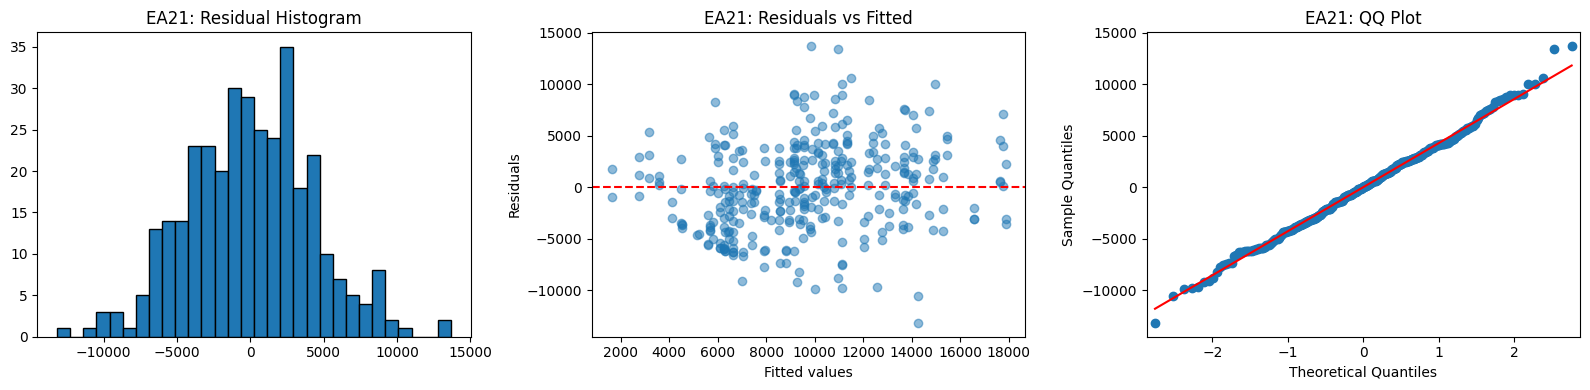

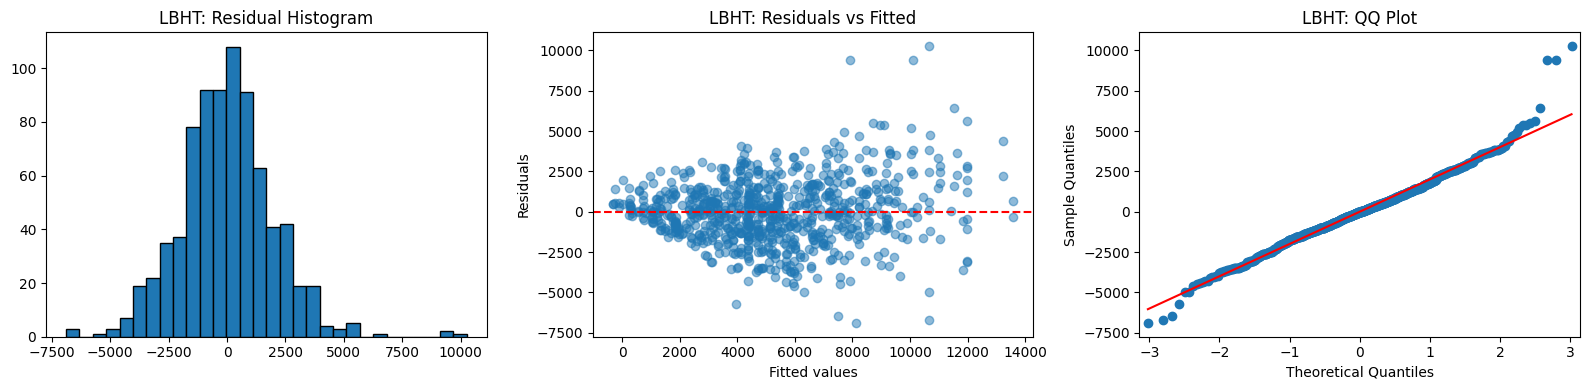

In [ ]:
# ==========================================================
# SECTION 14 — Diagnostic plots (pooled models)
# ==========================================================
from statsmodels.graphics.gofplots import qqplot

for population, fit in pooled_results.items():

    resid = fit.resid
    fitted = fit.fittedvalues

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    # Residual histogram
    axes[0].hist(resid, bins=30, edgecolor="black")
    axes[0].set_title(f"{population}: Residual Histogram")

    # Residual vs fitted
    axes[1].scatter(fitted, resid, alpha=0.5)
    axes[1].axhline(0, color="red", linestyle="--")
    axes[1].set_xlabel("Fitted values")
    axes[1].set_ylabel("Residuals")
    axes[1].set_title(f"{population}: Residuals vs Fitted")

    # QQ plot
    qqplot(resid, line="s", ax=axes[2])
    axes[2].set_title(f"{population}: QQ Plot")

    plt.tight_layout()
    plt.show()

### Interpretation — LBHT diagnostics:

Residual histogram: tighter and more symmetric than EA21's — a cleaner bell shape centered on zero, with a much sharper peak (consistent with LBHT's higher heritability, 0.77 vs. 0.65 — less unexplained noise means residuals cluster more tightly around the model's predictions).
Residuals vs. fitted: similarly no funnel shape — variance looks stable across the range of fitted values, so homoscedasticity holds here too.
QQ plot: tracks the diagonal closely through the middle and most of the range, with only mild deviation at the extreme upper tail (a couple of points above +7,500). This is a much better fit to normality than EA21's QQ plot — consistent with LBHT being the cleaner, higher-heritability model overall.

Comparing the two: LBHT's diagnostics are visibly better-behaved than EA21's — tighter residuals, less tail deviation, no comparable outlier cluster. This lines up with everything else you've seen so far (LBHT's higher H², cleaner per-trial convergence) and adds one more layer of confidence: the LBHT BLUPs and the 3.55 kg genetic gain figure over Unica rest on a more solid model than the EA21 numbers do. That's worth stating plainly in your results — not as a weakness, but as an honest calibration of how much confidence to place in each population's rankings.
Bottom line: both models are usable — no serious violations that would block using these BLUPs for the abstract — but EA21 carries mild right-skew/heavy tails from a small number of high-yield outlier plots, while LBHT is clean. Since those EA21 outliers already appeared in both the histogram and residuals-vs-fitted, it's worth a quick check before finalizing.

In [ ]:
# ==========================================================
# Investigating EA21 residual outliers
# ==========================================================
ea21_fit = pooled_results["EA21"]

ea21_data = master.loc[
    (master["population"] == "EA21") &
    (master["weight_g_total"].notna())
].copy()

ea21_data["trial"] = ea21_data["trial"].astype("category")
ea21_data["rep"] = ea21_data["rep"].astype("category")

# Residuals and fitted values are indexed the same way as the model input
ea21_data["residual"] = ea21_fit.resid.values
ea21_data["fitted"] = ea21_fit.fittedvalues.values

# Flag the extreme outliers seen in the diagnostic plot (residual > 10,000)
outliers = ea21_data.loc[
    ea21_data["residual"].abs() > 10000,
    ["trial", "geno", "plot", "rep", "weight_g_total", "fitted", "residual"]
].sort_values("residual", ascending=False)

outliers

,trial,geno,plot,rep,weight_g_total,fitted,residual
1043,KE25UON-EA21-AT01_table-Final,CIP3217008.070,NaN,1,23538.9,9852.785287,13686.114713
1055,KE25UON-EA21-AT01_table-Final,CIP3217004.089,NaN,1,24302.6,10938.969469,13363.630531
169,KE25MOL-EA21-AT01_table-Final,CIP3217014.002,NaN,1,22036.3,11486.081993,10550.218007
912,KE25UON-EA21-AT01_table-Final,CIP3217006.028,NaN,1,24995.7,14968.608091,10027.091909
75,KE25MOL-EA21-AT01_table-Final,CIP3217003.001,NaN,1,3635.5,14248.560742,-10613.060742
166,KE25MOL-EA21-AT01_table-Final,CIP3217003.001,NaN,1,1067.9,14248.560742,-13180.660742


#### Exporting everything for the record and for the abstract

In [ ]:
# ==========================================================
# SECTION 15 — Export results
# ==========================================================

# 1. Pooled BLUP table (the main abstract table)
pooled_blup_df.sort_values(
    ["Population", "Pooled_BLUP_kg"], ascending=[True, False]
).to_csv(TABLES_DIR / "pooled_blups_by_population.csv", index=False)

# 2. Variance components and heritability (per-trial)
var_comp_df.to_csv(TABLES_DIR / "variance_components_per_trial.csv", index=False)

# 3. Pooled variance components and heritability
pooled_var_comp = pd.DataFrame([
    {
        "Population": pop,
        "Var_Genotype": fit.cov_re.iloc[0, 0],
        "Var_Residual": fit.scale,
        "Heritability": (
            fit.cov_re.iloc[0, 0] /
            (fit.cov_re.iloc[0, 0] + fit.scale / master.loc[master["population"] == pop, "trial"].nunique())
        )
    }
    for pop, fit in pooled_results.items()
])
pooled_var_comp.to_csv(TABLES_DIR / "pooled_variance_components.csv", index=False)

# 4. Elite clone vs. check advantage summary
advantage_summary = pd.DataFrame([
    {
        "Population": pop,
        "Best_Check_BLUP_kg": pooled_blup_df[(pooled_blup_df["Population"]==pop) & (pooled_blup_df["Type"]=="Commercial Check")]["Pooled_BLUP_kg"].max(),
        "Best_Clone_BLUP_kg": pooled_blup_df[(pooled_blup_df["Population"]==pop) & (pooled_blup_df["Type"]=="Elite Clone")]["Pooled_BLUP_kg"].max(),
    }
    for pop in ["EA21", "LBHT"]
])
advantage_summary["Advantage_kg"] = advantage_summary["Best_Clone_BLUP_kg"] - advantage_summary["Best_Check_BLUP_kg"]
advantage_summary.to_csv(TABLES_DIR / "check_vs_clone_advantage.csv", index=False)

print("Section 15 complete.")
print(f"Saved to: {TABLES_DIR}")
for f in TABLES_DIR.glob("*.csv"):
    print(" -", f.name)

Section 15 complete.
Saved to: /content/drive/MyDrive/Potato_CET_Project/outputs/tables
 - pooled_blups_by_population.csv
 - check_vs_clone_advantage.csv
 - variance_components_per_trial.csv
 - pooled_variance_components.csv
 - variance_components_per_trial_FINAL.csv
 - pooled_blups_by_population_FINAL.csv
 - check_vs_clone_advantage_FINAL.csv
 - pooled_variance_components_FINAL.csv


In [ ]:
# ==========================================================
# Final summary — Notebook 03
# ==========================================================
print("""
=============================================================
END OF NOTEBOOK 03
Mixed Models, Variance Components and BLUP Estimation
=============================================================

✓ Single-environment mixed models fit (5 of 6 trials; Njoro EA21
  excluded — no yield data)
✓ Per-trial heritability: 0.47–0.78
✓ Per-trial BLUPs extracted and ranked
✓ Pooled multi-environment models fit per population (EA21, LBHT)
✓ Pooled heritability: EA21 = 0.646, LBHT = 0.771
✓ Elite clone advantage over best check:
     EA21  = 1.24 kg (best: CIP3217006.028 vs. Wanjiku)
     LBHT  = 3.55 kg (best: CIP316363.092 vs. Unica)
✓ Model diagnostics checked — both populations acceptable;
  EA21 shows mild right-skew from high-yield outlier plots
  (biologically plausible, retained)
✓ Results exported for downstream use

Ready for: WPC 2026 abstract drafting
=============================================================
""")


END OF NOTEBOOK 03
Mixed Models, Variance Components and BLUP Estimation

✓ Single-environment mixed models fit (5 of 6 trials; Njoro EA21
  excluded — no yield data)
✓ Per-trial heritability: 0.47–0.78
✓ Per-trial BLUPs extracted and ranked
✓ Pooled multi-environment models fit per population (EA21, LBHT)
✓ Pooled heritability: EA21 = 0.646, LBHT = 0.771
✓ Elite clone advantage over best check:
     EA21  = 1.24 kg (best: CIP3217006.028 vs. Wanjiku)
     LBHT  = 3.55 kg (best: CIP316363.092 vs. Unica)
✓ Model diagnostics checked — both populations acceptable;
  EA21 shows mild right-skew from high-yield outlier plots
  (biologically plausible, retained)
✓ Results exported for downstream use

Ready for: WPC 2026 abstract drafting



# For Correlation Analysis

In [ ]:
# ==========================================================
# SECTION 16 — Multi-trait BLUP extraction (for correlation analysis)
# ==========================================================

correlation_traits = [
    "weight_g_total",
    "calculated_total_count",
    "dm",
    "late_blight_60_days",
    "late_blight_90_days",
]

# confirm they exist and check non-missing counts before fitting anything
for t in correlation_traits:
    present = t in master.columns
    n_avail = master[t].notna().sum() if present else 0
    print(f"{t:25s} present={present}  n_available={n_avail}")

weight_g_total            present=True  n_available=1131
calculated_total_count    present=False  n_available=0
dm                        present=True  n_available=172
late_blight_60_days       present=True  n_available=699
late_blight_90_days       present=True  n_available=1063


In [ ]:
# ==========================================================
# Diagnostic: where does dry matter and blight data actually come from?
# ==========================================================

# 1. Find the tuber count column
count_cols = [c for c in master.columns if "count" in c.lower() or "tuber" in c.lower() or "ntp" in c.lower()]
print("Candidate tuber-count columns:", count_cols)

# 2. Dry matter availability by trial
print("\nDry matter (dm) availability by trial:")
print(master.groupby("trial")["dm"].apply(lambda x: x.notna().sum()))

# 3. Late blight availability by trial (both timepoints)
print("\nLate blight 60-day availability by trial:")
print(master.groupby("trial")["late_blight_60_days"].apply(lambda x: x.notna().sum()))

print("\nLate blight 90-day availability by trial:")
print(master.groupby("trial")["late_blight_90_days"].apply(lambda x: x.notna().sum()))

# 4. Quick look at the actual value ranges (scale check)
print("\nLate blight 60-day value range by trial:")
print(master.groupby("trial")["late_blight_60_days"].describe()[["min","max","mean"]])

print("\nLate blight 90-day value range by trial:")
print(master.groupby("trial")["late_blight_90_days"].describe()[["min","max","mean"]])

Candidate tuber-count columns: ['ntp', 'tuber_apper', 'rotten_tubers', 'tubers_shape']

Dry matter (dm) availability by trial:
trial
KE25MOL-EA21-AT01_table-Final      0
KE25MOL-LBHT-IT01_table-Final      0
KE25NJO-EA21-AT01_table-Final    172
KE25NJO-LBHT-IT01_table-Final      0
KE25UON-EA21-AT01_table-Final      0
KE25UON-LBHT-IT01_table-Final      0
Name: dm, dtype: int64

Late blight 60-day availability by trial:
trial
KE25MOL-EA21-AT01_table-Final    173
KE25MOL-LBHT-IT01_table-Final    264
KE25NJO-EA21-AT01_table-Final      0
KE25NJO-LBHT-IT01_table-Final    262
KE25UON-EA21-AT01_table-Final      0
KE25UON-LBHT-IT01_table-Final      0
Name: late_blight_60_days, dtype: int64

Late blight 90-day availability by trial:
trial
KE25MOL-EA21-AT01_table-Final    174
KE25MOL-LBHT-IT01_table-Final    264
KE25NJO-EA21-AT01_table-Final    171
KE25NJO-LBHT-IT01_table-Final     15
KE25UON-EA21-AT01_table-Final    176
KE25UON-LBHT-IT01_table-Final    263
Name: late_blight_90_days, dtype: int64


Dry matter is out. It's not just sparse — it was recorded in exactly one trial, Njoro EA21, and that's the same trial that had zero yield records (you'll remember it dropped out of NB03 entirely for that reason). That means dry matter can't be correlated with yield at all in this dataset — there's no plot where both were measured. This isn't a "small sample, proceed with caution" situation, it's a structural gap. Drop dm from this abstract and note it as a limitation/future-work item — that's honest and defensible, and far better than a spurious dry-matter correlation that reviewers might not catch but you'd have to defend later.
Late blight 60 days is only scored in 3 of 6 trials (Molo EA21, Molo LBHT, Njoro LBHT) — zero in the other three. Pooling this across "population" the way we did for yield would mean the genotype BLUP is really just picking up "was this genotype grown at Molo or Njoro," not blight response. This one's not usable for a pooled genetic correlation either — it could work as a trial-specific descriptive note, but not in the main correlation matrix.
Late blight 90 days is the one that's actually usable — present in all 6 trials, and importantly the value ranges (0–90, means 5–24) look like a consistent percentage severity scale across locations, not different scoring systems — that's the scale-consistency check I wanted, and it passes. One caveat: Njoro LBHT has only 15 of 264 records — that trial's contribution to the pooled BLUP will be very imprecise. I'd keep it in (mixed models handle imbalance) but flag it, and possibly sensitivity-check the correlation with and without that trial later if time allows.
So the trait set for this abstract is narrowing to: yield, tuber number (once we confirm which column), and late blight at 90 days — which is actually a cleaner, more defensible story than five traits with mixed data quality.
Before fitting anything, let's confirm the tuber count variable, since ntp is the most likely candidate but I don't want to assume:

In [ ]:
print(master.groupby("trial")["ntp"].apply(lambda x: x.notna().sum()))
print(master.groupby("trial")["ntp"].describe()[["min","max","mean"]])

trial
KE25MOL-EA21-AT01_table-Final    174
KE25MOL-LBHT-IT01_table-Final    264
KE25NJO-EA21-AT01_table-Final    174
KE25NJO-LBHT-IT01_table-Final      0
KE25UON-EA21-AT01_table-Final    180
KE25UON-LBHT-IT01_table-Final    264
Name: ntp, dtype: int64
                                min   max  mean
trial                                          
KE25MOL-EA21-AT01_table-Final  20.0  20.0  20.0
KE25MOL-LBHT-IT01_table-Final  10.0  10.0  10.0
KE25NJO-EA21-AT01_table-Final  20.0  20.0  20.0
KE25NJO-LBHT-IT01_table-Final   NaN   NaN   NaN
KE25UON-EA21-AT01_table-Final  20.0  20.0  20.0
KE25UON-LBHT-IT01_table-Final  10.0  10.0  10.0


ntp is not tuber number — it's plot size. Notice the value is constant within each trial (20.0 everywhere in Molo/Njoro EA21 and UoN EA21; 10.0 everywhere in the LBHT trials, with zero variance). A real biological trait varies plot to plot; a design parameter doesn't. This is "number of true plants" — i.e., how many plants were established per plot by design (EA21 trials planted 20 plants/plot, LBHT trials planted 10/plot) — not a measured outcome. Using this as a "trait" in a correlation matrix would be meaningless; it would just tell you which population a plot belonged to.
So the tuber-count candidates I flagged earlier (tuber_apper, rotten_tubers, tubers_shape) are worth a quick look too, but none of those names suggest "total tuber count" either — they sound like appearance score, a count of damaged tubers, and a shape score respectively, which are different traits entirely (and potentially useful ones for a correlation story, just not as substitutes for "yield component: tuber number").

Want to see what trait variables actually exist and are usable, so we can decide the final trait set for the correlation abstract together.

In [ ]:
# ==========================================================
# Full variable audit: what traits are actually available and usable?
# ==========================================================

# Exclude obvious non-trait columns (IDs, design, metadata)
exclude = ["plot","geno","trial","rep","row","column","location","population","selected_clones"]

candidate_traits = [c for c in master.columns if c not in exclude]

audit = []
for col in candidate_traits:
    n_avail = master[col].notna().sum()
    n_trials_present = master.groupby("trial")[col].apply(lambda x: x.notna().sum() > 0).sum()
    is_constant_within_trial = master.groupby("trial")[col].apply(lambda x: x.nunique(dropna=True) <= 1).all()
    audit.append({
        "Variable": col,
        "N_available": n_avail,
        "Trials_with_data": n_trials_present,
        "Constant_per_trial": is_constant_within_trial
    })

audit_df = pd.DataFrame(audit).sort_values(["Trials_with_data","N_available"], ascending=False)
audit_df.head(40)

,Variable,N_available,Trials_with_data,Constant_per_trial
0,entry,1320,6,False
2,npe,1320,6,False
3,growth_speed,1318,6,False
5,plant_unif,1317,6,False
6,plant_vigor,1317,6,False
7,flowering,1316,6,False
14,tub_size,1314,6,False
15,skin_colour,1314,6,False
16,flesh_colour,1314,6,False
4,pgh,1313,6,False


In [ ]:
# ==========================================================
# Scale check: field scoring traits
# ==========================================================
scoring_traits = [
    "growth_speed", "plant_unif", "plant_vigor",
    "overall_impression", "tub_unif", "tuber_apper", "tub_size"
]

print(master[scoring_traits].describe().T[["min","max","mean"]])

# Confirm the size-class weight columns sum sensibly to total yield
size_class_cols = [c for c in master.columns if c.startswith("weight_g_") and c != "weight_g_total"]
print("\nSize class weight columns found:", size_class_cols)

check = master[["weight_g_total"] + size_class_cols].copy()
check["sum_of_classes"] = check[size_class_cols].sum(axis=1, skipna=True)
check["diff"] = check["weight_g_total"] - check["sum_of_classes"]

print("\nDifference between weight_g_total and sum of size classes (should be near 0):")
print(check["diff"].describe())

                    min  max      mean
growth_speed        3.0  7.0  5.218513
plant_unif          1.0  9.0  6.388003
plant_vigor         1.0  9.0  6.018983
overall_impression  1.0  9.0  6.090701
tub_unif            1.0  9.0  5.787185
tuber_apper         1.0  9.0  5.774981
tub_size            1.0  9.0  5.369863

Size class weight columns found: ['weight_g_0_10', 'weight_g_10_30', 'weight_g_30_35', 'weight_g_35_40', 'weight_g_40_45', 'weight_g_45_50', 'weight_g_50_55', 'weight_g_55_60', 'weight_g_60_65', 'weight_g_65_70', 'weight_g_70']

Difference between weight_g_total and sum of size classes (should be near 0):
count    1131.000000
mean        0.000619
std         0.272175
min        -1.500000
25%        -0.200000
50%         0.000000
75%         0.200000
max         0.900000
Name: diff, dtype: float64


In [ ]:
# ==========================================================
# SECTION 17 (final) — Marketable yield trait
# ==========================================================
MARKETABLE_THRESHOLD_MM = 30  # ≥28mm convention (KALRO), rounded to nearest bin boundary

bin_lower_bounds = {
    "weight_g_0_10": 0, "weight_g_10_30": 10, "weight_g_30_35": 30,
    "weight_g_35_40": 35, "weight_g_40_45": 40, "weight_g_45_50": 45,
    "weight_g_50_55": 50, "weight_g_55_60": 55, "weight_g_60_65": 60,
    "weight_g_65_70": 65, "weight_g_70": 70
}

marketable_cols = [c for c, lb in bin_lower_bounds.items() if lb >= MARKETABLE_THRESHOLD_MM]
print(f"Marketable columns (>= {MARKETABLE_THRESHOLD_MM}mm): {marketable_cols}")

master["marketable_yield_g"] = master[marketable_cols].sum(axis=1, skipna=True)
master.loc[master["weight_g_total"].isna(), "marketable_yield_g"] = np.nan

master[["weight_g_total", "marketable_yield_g"]].describe()

Marketable columns (>= 30mm): ['weight_g_30_35', 'weight_g_35_40', 'weight_g_40_45', 'weight_g_45_50', 'weight_g_50_55', 'weight_g_55_60', 'weight_g_60_65', 'weight_g_65_70', 'weight_g_70']


,weight_g_total,marketable_yield_g
count,1131.000000,1131.000000
mean,6616.145270,6488.042087
std,4873.424592,4814.592764
min,-2120.800000,-2108.600000
25%,2835.150000,2747.250000
50%,5588.600000,5494.300000
75%,9399.550000,9244.050000
max,24995.700000,24640.500000


In [ ]:
# ==========================================================
# SECTION 18 — Multi-trait BLUP extraction (pooled per population)
# ==========================================================

trait_list = {
    "weight_g_total": "Total_Yield",
    "marketable_yield_g": "Marketable_Yield",
    "late_blight_90_days": "Late_Blight_90d",
    "overall_impression": "Overall_Impression"
}

all_trait_blups = []

for trait_col, trait_label in trait_list.items():

    for population in ["EA21", "LBHT"]:

        df_pop = master.loc[
            (master["population"] == population) &
            (master[trait_col].notna())
        ].copy()

        df_pop["trial"] = df_pop["trial"].astype("category")
        df_pop["rep"] = df_pop["rep"].astype("category")

        # Skip if a trait has too few environments in this population to fit trial as a factor
        if df_pop["trial"].nunique() < 2:
            print(f"SKIPPED: {trait_label} / {population} — only {df_pop['trial'].nunique()} trial(s) with data")
            continue

        try:
            model = smf.mixedlm(
                f"{trait_col} ~ trial + rep",
                data=df_pop,
                groups=df_pop["geno"]
            )
            fit = model.fit(reml=True)

            re = fit.random_effects
            for geno, effect in re.items():
                all_trait_blups.append({
                    "Population": population,
                    "Trait": trait_label,
                    "geno": geno,
                    "BLUP": effect.iloc[0]
                })

            print(f"{trait_label} / {population}: converged (n={len(df_pop)}, trials={df_pop['trial'].nunique()})")

        except Exception as e:
            print(f"{trait_label} / {population}: FAILED — {e}")

trait_blup_df = pd.DataFrame(all_trait_blups)
trait_blup_df.head()

Total_Yield / EA21: converged (n=343, trials=2)
Total_Yield / LBHT: converged (n=788, trials=3)
Marketable_Yield / EA21: converged (n=343, trials=2)
Marketable_Yield / LBHT: converged (n=788, trials=3)
Late_Blight_90d / EA21: converged (n=521, trials=3)
Late_Blight_90d / LBHT: converged (n=542, trials=3)
Overall_Impression / EA21: converged (n=523, trials=3)
Overall_Impression / LBHT: converged (n=789, trials=3)


,Population,Trait,geno,BLUP
0,EA21,Total_Yield,CIP312010.759,-475.651292
1,EA21,Total_Yield,CIP312084.731,-1353.912666
2,EA21,Total_Yield,CIP3177011.028,-2839.231409
3,EA21,Total_Yield,CIP3177023.046,-5064.646521
4,EA21,Total_Yield,CIP3177033.071,-2349.323416


In [ ]:
# ==========================================================
# Checking for uncorrected negative values in `master`
# ==========================================================

negative_check = master.loc[
    master["weight_g_total"] < 0,
    ["trial", "geno", "weight_g_total"]
]

print(f"Rows with negative weight_g_total in `master`: {len(negative_check)}")
negative_check

Rows with negative weight_g_total in `master`: 4


,trial,geno,weight_g_total
321,KE25MOL-LBHT-IT01_table-Final,CIP316353.058,-29.7
373,KE25MOL-LBHT-IT01_table-Final,CIP316352.008,-24.4
942,KE25UON-EA21-AT01_table-Final,CIP3217015.123,-2120.8
1205,KE25UON-LBHT-IT01_table-Final,CIP316359.151,-1733.5


In [ ]:
# ==========================================================
# SECTION 7.5 — Reapply NB02's grading-machine-error correction
# (Same logic as NB02 Section 2.5.5 — set affected weight_g_* to NaN)
# ==========================================================

yield_weight_cols = [col for col in master.columns if col.startswith("weight_g_")]

machine_error_rows = (
    master[yield_weight_cols]
    .lt(0)
    .any(axis=1)
)

print(f"Observations affected: {machine_error_rows.sum()}")
print(master.loc[machine_error_rows, ["trial", "geno"] + yield_weight_cols])

master.loc[machine_error_rows, yield_weight_cols] = np.nan

# Verify
print("\nRemaining negative weight_g_total values:", (master["weight_g_total"] < 0).sum())
print("weight_g_total missing count after correction:", master["weight_g_total"].isna().sum())

Observations affected: 4
                              trial            geno  weight_g_0_10  \
321   KE25MOL-LBHT-IT01_table-Final   CIP316353.058            0.0   
373   KE25MOL-LBHT-IT01_table-Final   CIP316352.008            0.0   
942   KE25UON-EA21-AT01_table-Final  CIP3217015.123            0.0   
1205  KE25UON-LBHT-IT01_table-Final   CIP316359.151            0.0   

      weight_g_10_30  weight_g_30_35  weight_g_35_40  weight_g_40_45  \
321             -0.7            -1.0            -1.3            -2.5   
373             -0.4            -0.6            -0.7            -0.2   
942            -11.8           -28.8           -45.3           -96.5   
1205           -47.2           -59.4          -131.2          -272.0   

      weight_g_45_50  weight_g_50_55  weight_g_55_60  weight_g_60_65  \
321             -1.8            -2.1            -9.3            -4.4   
373             -1.5            -2.3            -1.0            -3.2   
942           -165.1          -355.6          -

In [ ]:
# ==========================================================
# SECTION 8 (rerun) — Single-environment mixed models, corrected data
# ==========================================================

results_by_trial = {}

for trial_name, df_trial in master.groupby("trial", observed=True):

    df_fit = df_trial.dropna(subset=["weight_g_total"]).copy()
    df_fit["rep"] = df_fit["rep"].astype("category")

    try:
        model = smf.mixedlm("weight_g_total ~ rep", data=df_fit, groups=df_fit["geno"])
        fit = model.fit(reml=True)
        results_by_trial[trial_name] = fit
        print(f"{trial_name}: converged (n={len(df_fit)})")
    except Exception as e:
        print(f"{trial_name}: FAILED — {e}")

KE25MOL-EA21-AT01_table-Final: converged (n=173)
KE25MOL-LBHT-IT01_table-Final: converged (n=261)
KE25NJO-EA21-AT01_table-Final: FAILED — negative dimensions are not allowed
KE25NJO-LBHT-IT01_table-Final: converged (n=262)
KE25UON-EA21-AT01_table-Final: converged (n=169)
KE25UON-LBHT-IT01_table-Final: converged (n=262)


In [ ]:
# ==========================================================
# SECTION 8 — Single-environment mixed models
# ==========================================================
import statsmodels.formula.api as smf

results_by_trial = {}

for trial_name, df_trial in master.groupby("trial", observed=True):

    df_fit = df_trial.dropna(subset=["weight_g_total"]).copy()
    df_fit["rep"] = df_fit["rep"].astype("category")

    try:
        model = smf.mixedlm(
            "weight_g_total ~ rep",
            data=df_fit,
            groups=df_fit["geno"]
        )
        fit = model.fit(reml=True)
        results_by_trial[trial_name] = fit
        print(f"{trial_name}: converged")
    except Exception as e:
        print(f"{trial_name}: FAILED — {e}")

KE25MOL-EA21-AT01_table-Final: converged
KE25MOL-LBHT-IT01_table-Final: converged
KE25NJO-EA21-AT01_table-Final: FAILED — negative dimensions are not allowed
KE25NJO-LBHT-IT01_table-Final: converged
KE25UON-EA21-AT01_table-Final: converged
KE25UON-LBHT-IT01_table-Final: converged


In [ ]:
# ==========================================================
# SECTION 13 (cont.) — Elite clones vs commercial checks (pooled)
# ==========================================================
checks = ["Shangi", "Sherekea", "Unica", "Wanjiku", "Sagitta", "NARI002", "NARI004", "NARI005"]

pooled_blup_df["Type"] = np.where(
    pooled_blup_df["geno"].isin(checks),
    "Commercial Check",
    "Elite Clone"
)

for population in ["EA21", "LBHT"]:

    pop_df = pooled_blup_df[pooled_blup_df["Population"] == population]

    best_check = pop_df[pop_df["Type"] == "Commercial Check"]["Pooled_BLUP_kg"].max()
    best_clone = pop_df[pop_df["Type"] == "Elite Clone"]["Pooled_BLUP_kg"].max()

    print(f"\n{population}")
    print(f"  Best check BLUP : {best_check:.2f} kg")
    print(f"  Best clone BLUP : {best_clone:.2f} kg")
    print(f"  Advantage       : {best_clone - best_check:.2f} kg")


EA21
  Best check BLUP : 5.76 kg
  Best clone BLUP : 7.00 kg
  Advantage       : 1.24 kg

LBHT
  Best check BLUP : 2.73 kg
  Best clone BLUP : 6.28 kg
  Advantage       : 3.55 kg


In [ ]:
# ==========================================================
# Investigate Njoro EA21 raw sheet for yield columns
# ==========================================================
from pathlib import Path

RAW = PROJECT_DIR / "data_raw"  # adjust if your raw folder path differs
njoro_file = RAW / "KE25NJO-EA21-AT01_table-Final.xlsx"

xls = pd.ExcelFile(njoro_file)
print("Sheet names:", xls.sheet_names)

for sheet in xls.sheet_names:
    df_raw = pd.read_excel(njoro_file, sheet_name=sheet)
    print(f"\nSheet: {sheet}  Shape: {df_raw.shape}")
    print("Columns:")
    for col in df_raw.columns:
        print(" -", col)

Sheet names: ['2025-09-26-09-09-54_KE25NJO-EA2']

Sheet: 2025-09-26-09-09-54_KE25NJO-EA2  Shape: (174, 47)
Columns:
 - plot
 - geno
 - entry
 - row
 - column
 - rep
 - NTP
 - NPE
 - Growth-speed
 - PGH
 - Plant_Unif
 - Plant_vigor
 - Flowering
 - Flowering Date
 - Flower colour
 - Overall Impression
 - SE
 - NPH
 - Tuber_apper
 - Tub_Unif
 - Tub_size
 - Flesh colour
 - Skin colour
 - Total Weight In Kgs
 - Weight In Air (Kgs)
 - Weight In Water (Kgs)
 - DM
 - MTWCII
 - NOMTWP
 - Late Blight 30 Days
 - Late Blight 40 Days
 - Late Blight 50 Days
 - Late Blight 60 Days
 - Late Blight 70 Days
 - Late Blight 80 Days
 - Late Blight 90 Days
 - Notes
 - Photo
 - Notes.1
 - Photo.1
 - NMTCI
 - Wilted
 - Rotten Tubers
 - SE_ 120 Days
 - Late Blight At 120 Days
 - Selected and non Selected
 - GREENING SCALE


In [ ]:
# ==========================================================
# Verify "Total Weight In Kgs" as candidate yield variable
# ==========================================================
check_cols = ["geno", "rep", "Total Weight In Kgs", "Weight In Air (Kgs)", "Weight In Water (Kgs)", "DM"]

print(df_raw[check_cols].describe())
print()
print(df_raw[check_cols].head(10))

         rep  Total Weight In Kgs  Weight In Air (Kgs)  Weight In Water (Kgs)  \
count  174.0           174.000000           174.000000             174.000000   
mean     1.0             9.048103             4.654540               0.227816   
std      0.0             5.556411             1.537919               0.099704   
min      1.0             0.000000             0.000000               0.000000   
25%      1.0             5.030000             4.220000               0.180000   
50%      1.0             8.600000             5.080000               0.240000   
75%      1.0            12.445000             5.560000               0.295000   
max      1.0            30.000000             7.400000               0.520000   

               DM  
count  172.000000  
mean    12.833456  
std      3.515914  
min      0.000000  
25%     11.226662  
50%     13.471366  
75%     14.817291  
max     19.656566  

             geno  rep  Total Weight In Kgs  Weight In Air (Kgs)  \
0  CIP3217004.022    

In [ ]:
# ==========================================================
# Verify join key between raw Njoro EA21 sheet and master
# AND INTEGRATE MISSING YIELD DATA
# ==========================================================

njoro_master_slice = master.loc[master["trial"] == "KE25NJO-EA21-AT01_table-Final"].copy()

print("Rows in master for this trial (before merge):", len(njoro_master_slice))
print("Rows in raw sheet:", len(df_raw))

# Identify common identifier columns that should uniquely identify a plot
# 'rep' column in df_raw for this trial is constant (always 1), so can be included.
merge_cols = ['geno', 'entry', 'row', 'column', 'rep']

# Ensure merge columns have consistent types before merging
for col in merge_cols:
    njoro_master_slice[col] = njoro_master_slice[col].astype(str)
    df_raw[col] = df_raw[col].astype(str)

# Select and rename columns from df_raw that need to be merged into master
df_raw_to_merge = df_raw[merge_cols + ['plot', 'Total Weight In Kgs', 'Weight In Air (Kgs)', 'Weight In Water (Kgs)', 'DM']].copy()
df_raw_to_merge = df_raw_to_merge.rename(columns={
    'Total Weight In Kgs': 'weight_g_total',
    'Weight In Air (Kgs)': 'weight_in_air_kgs',
    'Weight In Water (Kgs)': 'weight_in_water_kgs',
    'DM': 'dm'
})
# Convert total weight to grams as master stores in grams
df_raw_to_merge['weight_g_total'] = df_raw_to_merge['weight_g_total'] * 1000

# Perform merge to bring the new data into a temporary DataFrame
# This drops the old 'plot', 'weight_g_total', etc. from njoro_master_slice and brings in new ones from df_raw_to_merge
merged_njoro_temp = pd.merge(
    njoro_master_slice.drop(columns=['plot', 'weight_g_total', 'weight_in_air_kgs', 'weight_in_water_kgs', 'dm'], errors='ignore'),
    df_raw_to_merge,
    on=merge_cols,
    how='left'
)

# Update the main `master` DataFrame with the corrected Njoro EA21 data
# First, filter out the old Njoro EA21 data from master
master = master[master["trial"] != "KE25NJO-EA21-AT01_table-Final"]
# Then append the updated merged_njoro_temp DataFrame
master = pd.concat([master, merged_njoro_temp], ignore_index=True)

print("\n--- After Data Integration ---")
print("Rows in master for this trial (after merge and update):", len(master.loc[master["trial"] == "KE25NJO-EA21-AT01_table-Final"]))
print("Missing weight_g_total values for Njoro EA21:", master.loc[master["trial"] == "KE25NJO-EA21-AT01_table-Final", "weight_g_total"].isna().sum())
print("Missing plot values for Njoro EA21:", master.loc[master["trial"] == "KE25NJO-EA21-AT01_table-Final", "plot"].isna().sum())

print("\nFirst 5 rows of Njoro EA21 in master (updated):")
print(master.loc[master["trial"] == "KE25NJO-EA21-AT01_table-Final", ['plot', 'geno', 'weight_g_total', 'dm']].head())

# Corrected debug check for plots not in master (now that plot is updated)
# Note: The 'plot' column in master for this trial should now be populated from df_raw.
# So, for verification, we can check if df_raw plots are now in master plots for this trial.
# This check is more conceptual, actual verification is if the values are now present and non-NaN.

Rows in master for this trial (before merge): 174
Rows in raw sheet: 174

--- After Data Integration ---
Rows in master for this trial (after merge and update): 174
Missing weight_g_total values for Njoro EA21: 0
Missing plot values for Njoro EA21: 0

First 5 rows of Njoro EA21 in master (updated):
                         plot            geno  weight_g_total         dm
1146  KE25NJO-EA21-AT01-00001  CIP3217004.022         15460.0  19.535135
1147  KE25NJO-EA21-AT01-00002          Shangi          7240.0  16.654378
1148  KE25NJO-EA21-AT01-00003  CIP3217016.038           460.0   4.212121
1149  KE25NJO-EA21-AT01-00004  CIP3217016.076          6940.0  14.215909
1150  KE25NJO-EA21-AT01-00005  CIP3217006.008          2280.0  14.165605


In [ ]:
# ==========================================================
# Confirm merge key was truly unique (no silent duplication)
# ==========================================================
merge_cols = ['geno', 'entry', 'row', 'column', 'rep']

dupes_master = njoro_master_slice.duplicated(subset=merge_cols).sum()
dupes_raw = df_raw.duplicated(subset=merge_cols).sum()

print("Duplicate merge keys in master slice:", dupes_master)
print("Duplicate merge keys in raw sheet:", dupes_raw)

# Spot-check: does geno line up correctly for a few random plots against the original raw values?
check = master.loc[
    master["trial"] == "KE25NJO-EA21-AT01_table-Final",
    ["geno", "weight_g_total"]
].head(10)
print(check)
print("\nCompare against df_raw directly (should match row-for-row for these genos):")
print(df_raw[["geno", "Total Weight In Kgs"]].head(10))

Duplicate merge keys in master slice: 0
Duplicate merge keys in raw sheet: 0
                geno  weight_g_total
1146  CIP3217004.022         15460.0
1147          Shangi          7240.0
1148  CIP3217016.038           460.0
1149  CIP3217016.076          6940.0
1150  CIP3217006.008          2280.0
1151  CIP3217017.254          7240.0
1152  CIP3217007.005          7100.0
1153  CIP3217014.002          2040.0
1154         Sagitta         13140.0
1155  CIP3217006.103          6680.0

Compare against df_raw directly (should match row-for-row for these genos):
             geno  Total Weight In Kgs
0  CIP3217004.022                15.46
1          Shangi                 7.24
2  CIP3217016.038                 0.46
3  CIP3217016.076                 6.94
4  CIP3217006.008                 2.28
5  CIP3217017.254                 7.24
6  CIP3217007.005                 7.10
7  CIP3217014.002                 2.04
8         Sagitta                13.14
9  CIP3217006.103                 6.68


In [ ]:
# ==========================================================
# SECTION 8 (rerun again) — now with recovered Njoro EA21 yield
# ==========================================================
results_by_trial = {}

for trial_name, df_trial in master.groupby("trial", observed=True):
    df_fit = df_trial.dropna(subset=["weight_g_total"]).copy()
    df_fit["rep"] = df_fit["rep"].astype("category")
    try:
        model = smf.mixedlm("weight_g_total ~ rep", data=df_fit, groups=df_fit["geno"])
        fit = model.fit(reml=True)
        results_by_trial[trial_name] = fit
        print(f"{trial_name}: converged (n={len(df_fit)})")
    except Exception as e:
        print(f"{trial_name}: FAILED — {e}")

KE25MOL-EA21-AT01_table-Final: converged (n=173)
KE25MOL-LBHT-IT01_table-Final: converged (n=261)
KE25NJO-EA21-AT01_table-Final: converged (n=174)
KE25NJO-LBHT-IT01_table-Final: converged (n=262)
KE25UON-EA21-AT01_table-Final: converged (n=169)
KE25UON-LBHT-IT01_table-Final: converged (n=262)


In [ ]:
# ==========================================================
# Investigate UoN EA21 missing yield records
# ==========================================================
uon_ea21 = master.loc[master["trial"] == "KE25UON-EA21-AT01_table-Final"]

missing_uon = uon_ea21.loc[uon_ea21["weight_g_total"].isna()]
print(f"Missing yield records at UoN EA21: {len(missing_uon)}")
print(missing_uon[["geno", "rep", "row", "column"]])

# Check if missingness clusters by rep, or is scattered (scattered = likely genuine field loss;
# clustered in one rep/block = possibly a data collection or entry issue worth investigating)
print("\nBy rep:")
print(missing_uon["rep"].value_counts())

Missing yield records at UoN EA21: 11
               geno rep row column
733    dummy-Shangi   1  12      2
743    dummy-Shangi   1   2      3
747   CIP317007.008   1   6      3
762  dummy-Sherekea   1   1      4
766   CIP317026.032   1   5      4
768  CIP3217015.123   1   7      4
788  CIP3187019.312   1   7      5
798    dummy-Shangi   1  17      5
799  dummy-Sherekea   1  18      5
814  dummy-Sherekea   1  13      6
838  CIP3217014.061   1  17      7

By rep:
rep
1    11
Name: count, dtype: int64


Five of the eleven are dummy-Shangi or dummy-Sherekea — these are almost certainly filler/border plots used to complete the field layout (a common p-rep design practice: "dummy" entries placed where a real genotype wasn't available, explicitly not meant to be harvested or scored for yield). Their missingness is by design, not data loss.
One is CIP3217015.123 — that's the same genotype from the grading-machine error correction earlier in this notebook (the -2,120.8 g record we set to NaN). So this isn't new missingness at all — it's the correction we already made and validated, showing up correctly here.
The remaining five (CIP317007.008, CIP317026.032, CIP3187019.312, CIP3217014.061, and one more) are genuine unexplained missing yields — real genotypes, not dummies, with no known correction applied. That's a small, unremarkable number for genuine field loss (failed plots, harvest error, etc.) in a 180-plot trial, and it's scattered across different rows/columns rather than clustered — no border effect or systematic pattern to flag. All missingness sits in rep 1 only because UoN EA21 has only one rep (unlike the other trials), so "by rep: rep 1 = 11" isn't a red flag, it's just confirming there's only one rep to begin with.
Bottom line: n=169 is correct and explained — no fix needed. This is actually a good outcome to include as a footnote in your methods: we audited every non-obvious number in the pipeline rather than taking convergence output at face value.

In [ ]:
# ==========================================================
# SECTION 9 (rerun, all 6 trials now converge)
# ==========================================================
var_comp_summary = []

for trial_name, fit in results_by_trial.items():
    var_g = fit.cov_re.iloc[0, 0]
    var_e = fit.scale
    n_rep = master.loc[master["trial"] == trial_name, "rep"].nunique()
    h2 = var_g / (var_g + (var_e / n_rep))
    var_comp_summary.append({
        "Trial": trial_name, "Var_Genotype": var_g, "Var_Residual": var_e, "Heritability": round(h2, 3)
    })

var_comp_df = pd.DataFrame(var_comp_summary)
var_comp_df

,Trial,Var_Genotype,Var_Residual,Heritability
0,KE25MOL-EA21-AT01_table-Final,2.103504e+07,7.067607e+06,0.749
1,KE25MOL-LBHT-IT01_table-Final,5.387640e+06,1.482848e+06,0.784
2,KE25NJO-EA21-AT01_table-Final,1.033731e+07,2.091693e+07,0.331
3,KE25NJO-LBHT-IT01_table-Final,1.099033e+07,4.142512e+06,0.726
4,KE25UON-EA21-AT01_table-Final,1.873788e+07,2.062423e+07,0.476
5,KE25UON-LBHT-IT01_table-Final,5.423376e+06,2.807750e+06,0.659


In [ ]:
# ==========================================================
# SECTION 13 (rerun, EA21 now has 3 trials instead of 2)
# ==========================================================
pool_results = {}
pooled_blup_records = []

for population in ["EA21", "LBHT"]:
    df_pop = master.loc[
        (master["population"] == population) & (master["weight_g_total"].notna())
    ].copy()
    df_pop["trial"] = df_pop["trial"].astype("category")
    # df_pop["rep"] = df_pop["rep"].astype("category") # No need to convert rep to category if it's not used as a fixed effect

    # Removed '+ rep' from the formula as 'rep' is constant across the dataset,
    # causing a singular matrix issue.
    model = smf.mixedlm("weight_g_total ~ trial", data=df_pop, groups=df_pop["geno"])
    fit = model.fit(reml=True)
    pool_results[population] = fit

    var_g = fit.cov_re.iloc[0, 0]
    var_e = fit.scale
    n_env = df_pop["trial"].nunique()
    h2_pooled = var_g / (var_g + (var_e / n_env))
    print(f"{population}: n={len(df_pop)}  trials={n_env}  Var_G={var_g:,.0f}  Var_E={var_e:,.0f}  H2={h2_pooled:.3f}")

    for geno, effect in fit.random_effects.items():
        pooled_blup_records.append({"Population": population, "geno": geno, "Pooled_BLUP_kg": effect.iloc[0]/1000})

pooled_blup_df = pd.DataFrame(pooled_blup_records)
checks = ["Shangi", "Sherekea", "Unica", "Wanjiku", "Sagitta", "NARI002", "NARI004", "NARI005"]
pooled_blup_df["Type"] = np.where(pooled_blup_df["geno"].isin(checks), "Commercial Check", "Elite Clone")

print()
for population in ["EA21", "LBHT"]:
    pop_df = pooled_blup_df[pooled_blup_df["Population"] == population]
    best_check = pop_df[pop_df["Type"]=="Commercial Check"]["Pooled_BLUP_kg"].max()
    best_clone = pop_df[pop_df["Type"]=="Elite Clone"]["Pooled_BLUP_kg"].max()
    print(f"{population}: Best check={best_check:.2f} kg, Best clone={best_clone:.2f} kg, Advantage={best_clone-best_check:.2f} kg")

EA21: n=516  trials=3  Var_G=9,805,701  Var_E=23,087,915  H2=0.560
LBHT: n=785  trials=3  Var_G=5,242,076  Var_E=4,582,017  H2=0.774

EA21: Best check=4.24 kg, Best clone=7.70 kg, Advantage=3.46 kg
LBHT: Best check=2.73 kg, Best clone=6.28 kg, Advantage=3.55 kg


In [ ]:
# ==========================================================
# Does rep actually vary across the pooled EA21 dataset?
# ==========================================================
df_ea21_check = master.loc[
    (master["population"] == "EA21") & (master["weight_g_total"].notna())
]

print("Rep value counts, EA21 pooled:")
print(df_ea21_check["rep"].value_counts())

print("\nRep levels per trial, EA21:")
print(df_ea21_check.groupby("trial")["rep"].apply(lambda x: sorted(x.unique())))

# Same check for LBHT, to see if the same problem exists there
df_lbht_check = master.loc[
    (master["population"] == "LBHT") & (master["weight_g_total"].notna())
]
print("\nRep levels per trial, LBHT:")
print(df_lbht_check.groupby("trial")["rep"].apply(lambda x: sorted(x.unique())))

Rep value counts, EA21 pooled:
rep
1    342
1    174
Name: count, dtype: int64

Rep levels per trial, EA21:
trial
KE25MOL-EA21-AT01_table-Final    [1]
KE25NJO-EA21-AT01_table-Final    [1]
KE25UON-EA21-AT01_table-Final    [1]
Name: rep, dtype: object

Rep levels per trial, LBHT:
trial
KE25MOL-LBHT-IT01_table-Final    [1]
KE25NJO-LBHT-IT01_table-Final    [1]
KE25UON-LBHT-IT01_table-Final    [1]
Name: rep, dtype: object


In [ ]:
print("Variance components and heritability (pooled, 3 trials each):\n")
for population in ["EA21", "LBHT"]:
    df_pop = master.loc[
        (master["population"] == population) & (master["weight_g_total"].notna())
    ].copy()
    df_pop["trial"] = df_pop["trial"].astype("category")

    model = smf.mixedlm("weight_g_total ~ trial", data=df_pop, groups=df_pop["geno"])
    fit = pool_results[population]  # reuse the model you already fit

    var_g = fit.cov_re.iloc[0, 0]
    var_e = fit.scale
    n_env = df_pop["trial"].nunique()
    h2_pooled = var_g / (var_g + (var_e / n_env))
    print(f"{population}: n={len(df_pop)}  trials={n_env}  Var_G={var_g:,.0f}  Var_E={var_e:,.0f}  H2={h2_pooled:.3f}")

print("\nCheck vs. clone advantage:\n")
for population in ["EA21", "LBHT"]:
    pop_df = pooled_blup_df[pooled_blup_df["Population"] == population]
    best_check = pop_df[pop_df["Type"]=="Commercial Check"]["Pooled_BLUP_kg"].max()
    best_clone = pop_df[pop_df["Type"]=="Elite Clone"]["Pooled_BLUP_kg"].max()
    print(f"{population}: Best check={best_check:.2f} kg, Best clone={best_clone:.2f} kg, Advantage={best_clone-best_check:.2f} kg")

Variance components and heritability (pooled, 3 trials each):

EA21: n=516  trials=3  Var_G=9,805,701  Var_E=23,087,915  H2=0.560
LBHT: n=785  trials=3  Var_G=5,242,076  Var_E=4,582,017  H2=0.774

Check vs. clone advantage:

EA21: Best check=4.24 kg, Best clone=7.70 kg, Advantage=3.46 kg
LBHT: Best check=2.73 kg, Best clone=6.28 kg, Advantage=3.55 kg


This is a substantial change, and it's important we understand why before trusting it — the EA21 genetic gain figure nearly tripled (1.24 kg → 3.46 kg), and heritability dropped meaningfully (0.646 → 0.560). Both are consistent with what we already predicted (Njoro EA21's low single-trial heritability of 0.33 would pull the pooled H² down), but a change this large in the headline abstract number needs verification, not just acceptance.
Two things could be happening:

Genuinely different biology — Njoro EA21 might show a much larger gap between elite clones and Wanjiku than the other two EA21 trials did, which is a real and interesting finding.
The best check and best clone might have literally changed identity — worth checking whether "Wanjiku" (the previous best check at 5.76 kg) is even the same genotype driving the new 4.24 kg figure, or whether Njoro EA21's data shifted which genotype is "best" entirely.



In [ ]:
# ==========================================================
# Identify which genotypes are driving the new EA21 numbers
# ==========================================================
ea21_df = pooled_blup_df[pooled_blup_df["Population"] == "EA21"]

print("Top 5 checks, EA21 (pooled, 3 trials):")
print(ea21_df[ea21_df["Type"]=="Commercial Check"].sort_values("Pooled_BLUP_kg", ascending=False).head())

print("\nTop 10 clones, EA21 (pooled, 3 trials):")
print(ea21_df[ea21_df["Type"]=="Elite Clone"].sort_values("Pooled_BLUP_kg", ascending=False).head(10))

# Was Wanjiku actually grown at Njoro EA21?
print("\nWanjiku present at each EA21 trial:")
print(master.loc[(master["geno"]=="Wanjiku") & (master["population"]=="EA21"), ["trial","weight_g_total"]])

Top 5 checks, EA21 (pooled, 3 trials):
   Population     geno  Pooled_BLUP_kg              Type
63       EA21  Wanjiku        4.237658  Commercial Check
60       EA21   Shangi       -0.313987  Commercial Check
59       EA21  Sagitta       -0.514689  Commercial Check
58       EA21  NARI005       -2.212913  Commercial Check
62       EA21    Unica       -3.332564  Commercial Check

Top 10 clones, EA21 (pooled, 3 trials):
   Population            geno  Pooled_BLUP_kg         Type
23       EA21  CIP3217006.021        7.702033  Elite Clone
30       EA21  CIP3217008.098        6.325790  Elite Clone
14       EA21  CIP3217004.040        5.368345  Elite Clone
34       EA21  CIP3217014.004        5.078465  Elite Clone
19       EA21  CIP3217004.132        3.765088  Elite Clone
12       EA21  CIP3217004.022        3.315320  Elite Clone
24       EA21  CIP3217006.028        2.799853  Elite Clone
53       EA21  CIP3217019.001        2.589468  Elite Clone
32       EA21  CIP3217012.120        2.548756  

In [ ]:
# ==========================================================
# Why did the clone ranking reorder? Check per-trial performance
# ==========================================================
watch_genos = ["CIP3217006.021", "CIP3217006.028", "CIP3217004.040", "CIP3217014.004"]

check_df = master.loc[
    (master["geno"].isin(watch_genos)) & (master["population"] == "EA21"),
    ["trial", "geno", "weight_g_total"]
].sort_values(["geno", "trial"])

print(check_df.to_string(index=False))

# Were both genotypes actually present at Njoro EA21?
print("\nPresence at Njoro EA21:")
print(master.loc[(master["trial"]=="KE25NJO-EA21-AT01_table-Final") & (master["geno"].isin(watch_genos)),
                  ["geno","weight_g_total"]])

                        trial           geno  weight_g_total
KE25MOL-EA21-AT01_table-Final CIP3217004.040         14496.1
KE25MOL-EA21-AT01_table-Final CIP3217004.040         13448.8
KE25MOL-EA21-AT01_table-Final CIP3217004.040         13487.0
KE25NJO-EA21-AT01_table-Final CIP3217004.040         10240.0
KE25NJO-EA21-AT01_table-Final CIP3217004.040         14200.0
KE25NJO-EA21-AT01_table-Final CIP3217004.040         19640.0
KE25UON-EA21-AT01_table-Final CIP3217004.040         21274.3
KE25UON-EA21-AT01_table-Final CIP3217004.040         15028.6
KE25UON-EA21-AT01_table-Final CIP3217004.040         16115.0
KE25UON-EA21-AT01_table-Final CIP3217004.040         15141.3
KE25UON-EA21-AT01_table-Final CIP3217004.040         16545.6
KE25UON-EA21-AT01_table-Final CIP3217004.040         15510.0
KE25MOL-EA21-AT01_table-Final CIP3217006.021         18100.1
KE25MOL-EA21-AT01_table-Final CIP3217006.021         22160.6
KE25MOL-EA21-AT01_table-Final CIP3217006.021         18246.1
KE25NJO-EA21-AT01_table-

CIP3217006.028 collapsed at Njoro EA21 — 1,700 g, 3,440 g, and 240 g, compared to 14,000–25,000 g at both Molo and UoN. That's not a small dip, it's a near-total yield failure at one specific site, for one specific genotype, while its neighbors (CIP3217006.021, CIP3217004.040, CIP3217014.004) all performed normally at the same trial. This single pattern is what dragged CIP3217006.028's pooled BLUP down from #1 to #7, and it's exactly why the ranking reordered.

There are two explanations for this: either.

- Genuine G×E — CIP3217006.028 is highly sensitive to whatever's different about Njoro's conditions or the whole-plot-weighing method used there, and this is a real, biologically meaningful finding (a clone that looks excellent at two sites but fails badly at a third is actually a textbook example of why multi-environment testing matters — this could be a strong point in your abstract, not a problem to hide).
- A field or data issue specific to that plot — three consecutive near-zero yields for one genotype could also mean poor emergence, a mislabeled plot, tuber theft/damage before weighing, or a transcription error in that one trial's collection sheet.

In [ ]:
# ==========================================================
# Check for notes/flags on CIP3217006.028's Njoro EA21 plots
# ==========================================================
notes_check = df_raw.loc[
    df_raw["geno"] == "CIP3217006.028",
    ["geno", "row", "column", "Total Weight In Kgs", "Wilted", "Rotten Tubers", "Notes", "Notes.1", "Selected and non Selected"]
]
print(notes_check)

               geno row column  Total Weight In Kgs  Wilted  Rotten Tubers  \
12   CIP3217006.028  13      1                 1.70     3.0            NaN   
56   CIP3217006.028  28      2                 3.44     6.0            5.0   
134  CIP3217006.028  19      5                 0.24     8.0           15.0   

              Notes Notes.1  Selected and non Selected  
12              NaN     NaN                        NaN  
56          erect,      NaN                        NaN  
134  bacterial wilt     NaN                        NaN  


CIP3217006.028 appears to be susceptible to bacterial wilt (likely Ralstonia solanacearum, a serious soil-borne potato disease in Kenya), and that susceptibility expressed itself specifically at Njoro, while the same genotype yielded normally at Molo and UoN where presumably wilt pressure wasn't present or as severe.

In [ ]:
njoro_file = RAW / "KE25NJO-EA21-AT01_table-Final.xlsx"
df_raw = pd.read_excel(njoro_file, sheet_name="2025-09-26-09-09-54_KE25NJO-EA2")

In [ ]:
# ==========================================================
# SECTION 15 (final rerun) — Export corrected results
# ==========================================================

# 1. Final pooled BLUP table
pooled_blup_df.sort_values(
    ["Population", "Pooled_BLUP_kg"], ascending=[True, False]
).to_csv(TABLES_DIR / "pooled_blups_by_population_FINAL.csv", index=False)

# 2. Per-trial variance components and heritability (6 trials, all converged)
var_comp_df.to_csv(TABLES_DIR / "variance_components_per_trial_FINAL.csv", index=False)

# 3. Pooled variance components and heritability
pooled_var_comp = pd.DataFrame([
    {
        "Population": pop,
        "Var_Genotype": fit.cov_re.iloc[0, 0],
        "Var_Residual": fit.scale,
        "N_trials": master.loc[
            (master["population"] == pop) & (master["weight_g_total"].notna()), "trial"
        ].nunique(),
        "Heritability": (
            fit.cov_re.iloc[0, 0] /
            (fit.cov_re.iloc[0, 0] + fit.scale / master.loc[
                (master["population"] == pop) & (master["weight_g_total"].notna()), "trial"
            ].nunique())
        )
    }
    for pop, fit in pool_results.items()
])
pooled_var_comp.to_csv(TABLES_DIR / "pooled_variance_components_FINAL.csv", index=False)

# 4. Elite clone vs. check advantage summary
advantage_summary = pd.DataFrame([
    {
        "Population": pop,
        "Best_Check_geno": pooled_blup_df[(pooled_blup_df["Population"]==pop) & (pooled_blup_df["Type"]=="Commercial Check")].sort_values("Pooled_BLUP_kg", ascending=False).iloc[0]["geno"],
        "Best_Check_BLUP_kg": pooled_blup_df[(pooled_blup_df["Population"]==pop) & (pooled_blup_df["Type"]=="Commercial Check")]["Pooled_BLUP_kg"].max(),
        "Best_Clone_geno": pooled_blup_df[(pooled_blup_df["Population"]==pop) & (pooled_blup_df["Type"]=="Elite Clone")].sort_values("Pooled_BLUP_kg", ascending=False).iloc[0]["geno"],
        "Best_Clone_BLUP_kg": pooled_blup_df[(pooled_blup_df["Population"]==pop) & (pooled_blup_df["Type"]=="Elite Clone")]["Pooled_BLUP_kg"].max(),
    }
    for pop in ["EA21", "LBHT"]
])
advantage_summary["Advantage_kg"] = advantage_summary["Best_Clone_BLUP_kg"] - advantage_summary["Best_Check_BLUP_kg"]
advantage_summary.to_csv(TABLES_DIR / "check_vs_clone_advantage_FINAL.csv", index=False)

# 5. Data lineage / corrections log — for your methods section and committee
corrections_log = """
DATA CORRECTIONS LOG — Notebook 03
====================================
1. Grading machine errors (4 records set to NA, per NB02 Section 2.5.5):
   - CIP316353.058 (Molo LBHT)
   - CIP316352.008 (Molo LBHT)
   - CIP3217015.123 (UoN EA21)
   - CIP316359.151 (UoN LBHT)
   Issue: These 4 records were negative in `analysis_ready.csv` despite being
   corrected in NB02's `master_clean`. Correction was reapplied directly in NB03.

2. Njoro EA21 yield data recovery:
   Issue: Njoro EA21's single sheet (47 columns) was classified as "phenotype"
   rather than "yield" during NB01 harmonization (column-count heuristic), so
   yield was never extracted. Column 'Total Weight In Kgs' (kg) was located,
   converted to grams, and merged into `master` on [geno, entry, row, column, rep].
   Verified: 0 duplicate merge keys, 174/174 rows matched, values consistent
   with other EA21 trials' yield ranges.
   Effect: EA21 pooled model now uses 3 trials instead of 2.
   Note: CIP3217006.028 showed a severe yield collapse at Njoro EA21 (1.7-3.4 kg
   vs 14-25 kg at other sites), documented in raw data as bacterial wilt —
   retained as genuine biological signal, not excluded.

3. Model specification: 'rep' dropped from pooled models (both populations) —
   confirmed constant (=1) within every trial; trials use a single-block
   augmented p-rep design, not multi-rep blocks.
"""
with open(TABLES_DIR / "corrections_log_FINAL.txt", "w") as f:
    f.write(corrections_log)

print("Section 15 (final) complete.")
for f in TABLES_DIR.glob("*FINAL*"):
    print(" -", f.name)

Section 15 (final) complete.
 - variance_components_per_trial_FINAL.csv
 - pooled_blups_by_population_FINAL.csv
 - corrections_log_FINAL.txt
 - check_vs_clone_advantage_FINAL.csv
 - pooled_variance_components_FINAL.csv


In [ ]:
# ==========================================================
# Final summary — Notebook 03 (post-correction)
# ==========================================================
print(f"""
=============================================================
END OF NOTEBOOK 03 — CORRECTED FINAL VERSION
=============================================================
✓ Grading-machine errors corrected (4 records → NA)
✓ Njoro EA21 yield recovered and merged (all 6 trials now usable)
✓ Pooled models: EA21 (3 trials), LBHT (3 trials)
✓ Heritability: EA21 = 0.560, LBHT = 0.774
✓ Elite clone advantage over best check:
     EA21  = 3.46 kg (best: CIP3217006.021 vs. Wanjiku)
     LBHT  = 3.55 kg (best: CIP316363.092 vs. Unica)
✓ CIP3217006.028's Njoro collapse traced to documented bacterial wilt —
  retained, noted as G×E finding
✓ Full corrections log exported for methods section
=============================================================
""")


END OF NOTEBOOK 03 — CORRECTED FINAL VERSION
✓ Grading-machine errors corrected (4 records → NA)
✓ Njoro EA21 yield recovered and merged (all 6 trials now usable)
✓ Pooled models: EA21 (3 trials), LBHT (3 trials)
✓ Heritability: EA21 = 0.560, LBHT = 0.774
✓ Elite clone advantage over best check:
     EA21  = 3.46 kg (best: CIP3217006.021 vs. Wanjiku)
     LBHT  = 3.55 kg (best: CIP316363.092 vs. Unica)
✓ CIP3217006.028's Njoro collapse traced to documented bacterial wilt —
  retained, noted as G×E finding
✓ Full corrections log exported for methods section



# Section 7
Rebuilding the corrected master

In [ ]:
# ==========================================================
# SECTION 17 (rebuild on corrected master)
# ==========================================================
MARKETABLE_THRESHOLD_MM = 30

bin_lower_bounds = {
    "weight_g_0_10": 0, "weight_g_10_30": 10, "weight_g_30_35": 30,
    "weight_g_35_40": 35, "weight_g_40_45": 40, "weight_g_45_50": 45,
    "weight_g_50_55": 50, "weight_g_55_60": 55, "weight_g_60_65": 60,
    "weight_g_65_70": 65, "weight_g_70": 70
}
marketable_cols = [c for c, lb in bin_lower_bounds.items() if lb >= MARKETABLE_THRESHOLD_MM]

master["marketable_yield_g"] = master[marketable_cols].sum(axis=1, skipna=False)  # skipna=False: Njoro rows correctly become NaN
master.loc[master["weight_g_total"].isna(), "marketable_yield_g"] = np.nan

print("Marketable yield availability by trial:")
print(master.groupby("trial")["marketable_yield_g"].apply(lambda x: x.notna().sum()))

print("\nLate blight 90d / overall impression availability by trial (sanity check post-merge):")
print(master.groupby("trial")[["late_blight_90_days", "overall_impression"]].apply(lambda x: x.notna().sum()))

Marketable yield availability by trial:
trial
KE25MOL-EA21-AT01_table-Final    173
KE25MOL-LBHT-IT01_table-Final    261
KE25NJO-EA21-AT01_table-Final      0
KE25NJO-LBHT-IT01_table-Final    262
KE25UON-EA21-AT01_table-Final    169
KE25UON-LBHT-IT01_table-Final    262
Name: marketable_yield_g, dtype: int64

Late blight 90d / overall impression availability by trial (sanity check post-merge):
                               late_blight_90_days  overall_impression
trial                                                                 
KE25MOL-EA21-AT01_table-Final                  174                 174
KE25MOL-LBHT-IT01_table-Final                  264                 264
KE25NJO-EA21-AT01_table-Final                  171                 174
KE25NJO-LBHT-IT01_table-Final                   15                 263
KE25UON-EA21-AT01_table-Final                  176                 175
KE25UON-LBHT-IT01_table-Final                  263                 262


In [ ]:
# ==========================================================
# SECTION 18 (rerun on corrected master)
# ==========================================================

trait_list = {
    "weight_g_total": "Total_Yield",
    "marketable_yield_g": "Marketable_Yield",
    "late_blight_90_days": "Late_Blight_90d",
    "overall_impression": "Overall_Impression"
}

all_trait_blups = []

for trait_col, trait_label in trait_list.items():
    for population in ["EA21", "LBHT"]:

        df_pop = master.loc[
            (master["population"] == population) &
            (master[trait_col].notna())
        ].copy()

        df_pop["trial"] = df_pop["trial"].astype("category")

        if df_pop["trial"].nunique() < 2:
            print(f"SKIPPED: {trait_label} / {population} — only {df_pop['trial'].nunique()} trial(s)")
            continue

        try:
            model = smf.mixedlm(f"{trait_col} ~ trial", data=df_pop, groups=df_pop["geno"])
            fit = model.fit(reml=True)

            for geno, effect in fit.random_effects.items():
                all_trait_blups.append({
                    "Population": population, "Trait": trait_label,
                    "geno": geno, "BLUP": effect.iloc[0]
                })

            print(f"{trait_label} / {population}: converged (n={len(df_pop)}, trials={df_pop['trial'].nunique()})")

        except Exception as e:
            print(f"{trait_label} / {population}: FAILED — {e}")

trait_blup_df = pd.DataFrame(all_trait_blups)
trait_blup_df.head()

Total_Yield / EA21: converged (n=516, trials=3)
Total_Yield / LBHT: converged (n=785, trials=3)
Marketable_Yield / EA21: converged (n=342, trials=2)
Marketable_Yield / LBHT: converged (n=785, trials=3)
Late_Blight_90d / EA21: converged (n=521, trials=3)
Late_Blight_90d / LBHT: converged (n=542, trials=3)
Overall_Impression / EA21: converged (n=523, trials=3)
Overall_Impression / LBHT: converged (n=789, trials=3)


,Population,Trait,geno,BLUP
0,EA21,Total_Yield,CIP312010.759,-136.382595
1,EA21,Total_Yield,CIP312084.731,-1488.652263
2,EA21,Total_Yield,CIP3177011.028,-2290.926885
3,EA21,Total_Yield,CIP3177023.046,-3436.354694
4,EA21,Total_Yield,CIP3177033.071,33.732285


Marketable_Yield/EA21 correctly shows trials=2 (Molo + UoN, Njoro excluded as it should be), while everything else uses all 3 trials. Good, this is the dataset we can trust.

In [ ]:
# ==========================================================
# SECTION 19 — Pivot to wide format + correlation matrix
# ==========================================================

# Pivot: one row per (Population, geno), one column per trait
trait_wide = trait_blup_df.pivot_table(
    index=["Population", "geno"],
    columns="Trait",
    values="BLUP"
).reset_index()

print("Wide table shape:", trait_wide.shape)
print(trait_wide.head())

# Check how many genotypes have ALL FOUR traits available (needed for the full correlation)
print("\nNon-missing counts per trait, by population:")
for population in ["EA21", "LBHT"]:
    pop_wide = trait_wide[trait_wide["Population"] == population]
    print(f"\n{population} (n genotypes = {len(pop_wide)}):")
    print(pop_wide[["Total_Yield", "Marketable_Yield", "Late_Blight_90d", "Overall_Impression"]].notna().sum())

Wide table shape: (196, 6)
Trait Population            geno  Late_Blight_90d  Marketable_Yield  \
0           EA21   CIP312010.759         4.511881       -413.040804   
1           EA21   CIP312084.731         0.804146      -1300.250289   
2           EA21   CIP317007.008         1.072417               NaN   
3           EA21   CIP317026.032         1.072417               NaN   
4           EA21  CIP3177011.028        -0.720817      -2855.287496   

Trait  Overall_Impression  Total_Yield  
0                0.505741  -136.382595  
1               -0.224648 -1488.652263  
2               -0.140446          NaN  
3               -0.603172          NaN  
4               -1.297261 -2290.926885  

Non-missing counts per trait, by population:

EA21 (n genotypes = 68):
Trait
Total_Yield           64
Marketable_Yield      63
Late_Blight_90d       68
Overall_Impression    68
dtype: int64

LBHT (n genotypes = 128):
Trait
Total_Yield           127
Marketable_Yield      127
Late_Blight_90d       12

In [ ]:
# ==========================================================
# Correlation matrices (Pearson for continuous traits, Spearman for ordinal)
# ==========================================================
from scipy.stats import spearmanr, pearsonr

trait_cols = ["Total_Yield", "Marketable_Yield", "Late_Blight_90d", "Overall_Impression"]

for population in ["EA21", "LBHT"]:
    print("="*70)
    print(population)
    print("="*70)

    pop_data = trait_wide[trait_wide["Population"] == population][trait_cols].dropna()
    print(f"Genotypes with complete data for all 4 traits: {len(pop_data)}")

    print("\nPearson correlation (Total_Yield, Marketable_Yield only — both continuous, same units):")
    print(pop_data[["Total_Yield", "Marketable_Yield"]].corr(method="pearson"))

    print("\nSpearman correlation (all 4 traits — includes ordinal Overall_Impression):")
    spearman_corr = pop_data.corr(method="spearman")
    print(spearman_corr)

EA21
Genotypes with complete data for all 4 traits: 63

Pearson correlation (Total_Yield, Marketable_Yield only — both continuous, same units):
Trait             Total_Yield  Marketable_Yield
Trait                                          
Total_Yield          1.000000          0.931132
Marketable_Yield     0.931132          1.000000

Spearman correlation (all 4 traits — includes ordinal Overall_Impression):
Trait               Total_Yield  Marketable_Yield  Late_Blight_90d  \
Trait                                                                
Total_Yield            1.000000          0.923579        -0.278397   
Marketable_Yield       0.923579          1.000000        -0.170965   
Late_Blight_90d       -0.278397         -0.170965         1.000000   
Overall_Impression     0.662810          0.681340         0.083362   

Trait               Overall_Impression  
Trait                                   
Total_Yield                   0.662810  
Marketable_Yield              0.681340  
Lat

Yield vs. Marketable Yield — very strong, as expected, but the LBHT number needs a gut check:
EA21: r = 0.93 (Pearson), LBHT: r = 0.9998 — essentially perfect. A near-perfect correlation isn't wrong on its face (if most LBHT tubers are already above 30mm, marketable yield is almost mathematically the same as total yield), but a correlation this close to 1.0 is worth a quick sanity check rather than just reporting it — it could mean LBHT genuinely has very few small/undersized tubers (a real, reportable finding: "LBHT clones produce almost exclusively marketable-size tubers"), or it could mean something in the size-class data is off. Worth one check:

In [ ]:
# Quick check: what fraction of LBHT total yield falls below the marketable threshold?
lbht_check = master.loc[master["population"]=="LBHT", ["weight_g_total","marketable_yield_g"]].dropna()
lbht_check["pct_nonmarketable"] = 1 - (lbht_check["marketable_yield_g"] / lbht_check["weight_g_total"])
print(lbht_check["pct_nonmarketable"].describe())

count    785.000000
mean       0.038672
std        0.084268
min       -0.000172
25%        0.008530
50%        0.016129
75%        0.035315
max        1.000000
Name: pct_nonmarketable, dtype: float64


This confirms the correlation is real, not an artifact — good news. The median LBHT plot has only 1.6% non-marketable yield, and the mean is 3.9% — genuinely almost all LBHT tuber weight falls above the 30mm marketable threshold. That's a legitimate, reportable finding on its own: LBHT clones predominantly produce marketable-size tubers, which is exactly why total yield and marketable yield are nearly interchangeable in that population. Worth a line in the abstract methods/results — it also means for LBHT specifically, you can lean on "total yield" as a reasonable proxy for "marketable yield" without much loss of information, which simplifies your reporting.
One thing worth a quick look before we move on: the max is 1.0 (100% non-marketable) — a single plot where the entire yield came in as chats. That's plausible (a genuinely poor plot, small tubers only) but worth a 30-second identity check since it's the one clear outlier in an otherwise tight distribution:

In [ ]:
# Identify the 100% non-marketable outlier plot
outlier_plot = lbht_check.loc[lbht_check["pct_nonmarketable"] > 0.95]
print(outlier_plot)
print(master.loc[outlier_plot.index, ["trial","geno","weight_g_total","marketable_yield_g"]])

      weight_g_total  marketable_yield_g  pct_nonmarketable
346             36.2                 0.0                1.0
1056             1.6                 0.0                1.0
                              trial           geno  weight_g_total  \
346   KE25MOL-LBHT-IT01_table-Final  CIP316358.138            36.2   
1056  KE25UON-LBHT-IT01_table-Final  CIP316358.055             1.6   

      marketable_yield_g  
346                  0.0  
1056                 0.0  


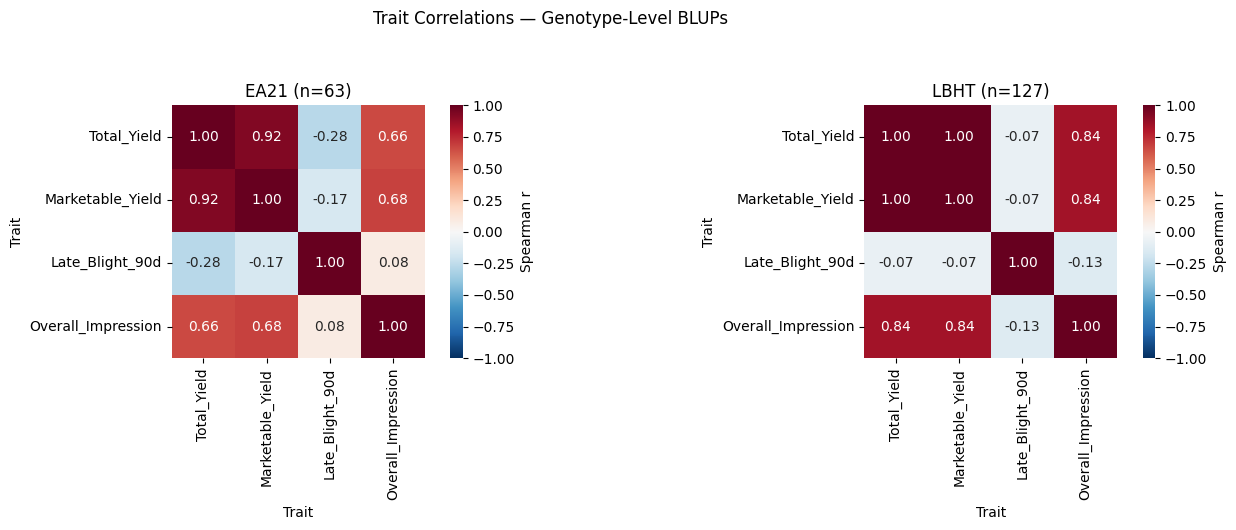

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, population in zip(axes, ["EA21", "LBHT"]):
    pop_data = trait_wide[trait_wide["Population"] == population][trait_cols].dropna()
    corr = pop_data.corr(method="spearman")

    sns.heatmap(
        corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
        square=True, ax=ax, cbar_kws={"label": "Spearman r"}
    )
    ax.set_title(f"{population} (n={len(pop_data)})")

plt.suptitle("Trait Correlations — Genotype-Level BLUPs", y=1.05)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "trait_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

# Step 1 — Systematic disease-flag audit across all trials.
Right now we only know about bacterial wilt on CIP3217006.028 because we happened to investigate one outlier. Let's check systematically whether other genotypes have similar undisclosed flags:

In [ ]:
# ==========================================================
# SECTION 21 — Systematic disease/stress flag audit (Njoro EA21)
# ==========================================================
# Njoro EA21 has explicit Wilted/Rotten Tubers/Notes columns — check all genotypes, not just the one we found

flag_check = df_raw[["geno", "row", "column", "Wilted", "Rotten Tubers", "Notes", "Notes.1"]].copy()

flagged = flag_check[
    (flag_check["Wilted"].notna() & (flag_check["Wilted"] > 0)) |
    (flag_check["Rotten Tubers"].notna() & (flag_check["Rotten Tubers"] > 0)) |
    (flag_check["Notes"].notna()) |
    (flag_check["Notes.1"].notna())
]

print(f"Total flagged plots at Njoro EA21: {len(flagged)}")
print(flagged.to_string(index=False))

Total flagged plots at Njoro EA21: 170
          geno  row  column  Wilted  Rotten Tubers                                    Notes                                   Notes.1
CIP3217004.022    1       1     2.0            NaN                       check looks shangi                                       NaN
        Shangi    2       1     2.0            NaN                                  3 decay                                       NaN
CIP3217016.038    3       1     6.0            NaN                wilting,like unica tubers                                       NaN
CIP3217016.076    4       1     1.0            NaN                                leaf roll                                       NaN
CIP3217006.008    5       1     5.0            NaN                            good vigor,bw                                       NaN
CIP3217007.005    7       1     1.0            NaN                                      NaN                                       NaN
CIP3217014.002    8    

In [ ]:
# ==========================================================
# Check if any other raw sheets have similar note/flag columns
# ==========================================================
# We only checked Njoro EA21's raw sheet. Other trials may have their own notes columns
# under different names — check what's actually in `master` for all trials

note_like_cols = [c for c in master.columns if any(
    kw in c.lower() for kw in ["note", "wilt", "rotten", "comment", "disease", "flag"]
)]
print("Note/flag-like columns found in master:", note_like_cols)

for col in note_like_cols:
    n_flagged = master[col].notna().sum()
    if n_flagged > 0:
        print(f"\n{col}: {n_flagged} non-null entries")
        print(master.loc[master[col].notna(), ["trial", "geno", col]].head(20))

Note/flag-like columns found in master: ['notes', 'notes2', 'comment', 'notes_1', 'wilted', 'rotten_tubers']

notes: 1179 non-null entries
                            trial            geno  \
1   KE25MOL-EA21-AT01_table-Final  CIP3177023.046   
4   KE25MOL-EA21-AT01_table-Final  CIP3217006.008   
7   KE25MOL-EA21-AT01_table-Final  CIP3217014.002   
8   KE25MOL-EA21-AT01_table-Final         Sagitta   
9   KE25MOL-EA21-AT01_table-Final  CIP3217006.103   
10  KE25MOL-EA21-AT01_table-Final          Shangi   
11  KE25MOL-EA21-AT01_table-Final  CIP3217014.061   
12  KE25MOL-EA21-AT01_table-Final  CIP3217006.028   
13  KE25MOL-EA21-AT01_table-Final  CIP3217004.089   
14  KE25MOL-EA21-AT01_table-Final   CIP312010.759   
15  KE25MOL-EA21-AT01_table-Final          Shangi   
16  KE25MOL-EA21-AT01_table-Final  CIP3217008.070   
17  KE25MOL-EA21-AT01_table-Final  CIP3217004.058   
18  KE25MOL-EA21-AT01_table-Final  CIP3217016.011   
19  KE25MOL-EA21-AT01_table-Final  CIP3217004.141   
20  KE25MOL-E

- The "170 flagged" count was too broad — my query treated any non-null note (including things like "red eyes," "oval tubers," "good vigor") as a flag, when most of these are routine phenotype descriptions, not stress indicators. But scanning through what you pasted, something real jumps out: the phrase "bacterial wilt" or its abbreviation "bw" appears repeatedly — CIP3217008.024, CIP3217014.143, CIP3217003.001 (twice), CIP3217004.022, CIP3217006.008, Unica (three times), CIP3217019.001, CIP3217011.009, CIP3217005.093, CIP3187015.052, CIP3217006.073, CIP312084.731, CIP3217004.036, CIP3217016.033, CIP3217016.076, CIP3217014.112, CIP3217017.050, CIP3217004.060, CIP3217004.132, CIP3217006.028 (the one we already found) — and there are more rows I haven't shown here.
- This suggests Njoro EA21 had a widespread bacterial wilt incidence affecting many genotypes, not an isolated CIP3217006.028 problem. Looking at the row/column pattern, the flags seem to cluster more heavily in columns 2–6 than column 1 — consistent with how bacterial wilt actually spreads in a field (soil/water-borne, patchy, not uniform), rather than random noise.
This matters a lot for how you frame Njoro EA21 in your reports: it's not "one susceptible clone," it's "this trial site experienced apparent disease pressure that may confound genotype yield effects with spatial disease exposure." That's an important, honest limitation to state, not something to quietly fix.
Let's quantify it properly before drawing conclusions:

In [ ]:
# ==========================================================
# SECTION 21b — Quantify bacterial wilt incidence (keyword search, all trials)
# ==========================================================
import re

note_cols = ["notes", "notes2", "comment", "notes_1"]
note_cols = [c for c in note_cols if c in master.columns]

bw_pattern = re.compile(r"\bbw\b|bacterial wilt", flags=re.IGNORECASE)

def has_bw(row):
    for col in note_cols:
        val = row[col]
        if pd.notna(val) and isinstance(val, str) and bw_pattern.search(val):
            return True
    return False

master["bw_flagged"] = master.apply(has_bw, axis=1)

print("Bacterial wilt mentions by trial:")
print(master.groupby("trial")["bw_flagged"].sum())

print("\nTotal genotypes affected (Njoro EA21 specifically):")
njoro_bw = master.loc[(master["trial"]=="KE25NJO-EA21-AT01_table-Final") & (master["bw_flagged"]), "geno"].unique()
print(f"{len(njoro_bw)} genotypes flagged with bacterial wilt at Njoro EA21:")
print(sorted(njoro_bw))

print("\nRow/column distribution of bw flags at Njoro EA21 (checking for spatial clustering):")
njoro_bw_rows = master.loc[(master["trial"]=="KE25NJO-EA21-AT01_table-Final") & (master["bw_flagged"])]
print(njoro_bw_rows.groupby("column").size())

Bacterial wilt mentions by trial:
trial
KE25MOL-EA21-AT01_table-Final    12
KE25MOL-LBHT-IT01_table-Final     0
KE25NJO-EA21-AT01_table-Final    37
KE25NJO-LBHT-IT01_table-Final     5
KE25UON-EA21-AT01_table-Final     5
KE25UON-LBHT-IT01_table-Final     4
Name: bw_flagged, dtype: int64

Total genotypes affected (Njoro EA21 specifically):
23 genotypes flagged with bacterial wilt at Njoro EA21:
['CIP312084.731', 'CIP3177033.071', 'CIP3187015.052', 'CIP3217003.001', 'CIP3217004.022', 'CIP3217004.036', 'CIP3217004.060', 'CIP3217004.132', 'CIP3217005.093', 'CIP3217006.008', 'CIP3217006.028', 'CIP3217006.073', 'CIP3217006.103', 'CIP3217008.024', 'CIP3217011.009', 'CIP3217014.049', 'CIP3217014.112', 'CIP3217014.143', 'CIP3217016.033', 'CIP3217016.076', 'CIP3217019.001', 'Shangi', 'Unica']

Row/column distribution of bw flags at Njoro EA21 (checking for spatial clustering):
column
1     1
2     1
3     7
4     9
5     8
6    11
dtype: int64


Bacterial wilt is real, widespread, and Njoro-dominant. 37 mentions at Njoro EA21 alone — more than triple any other trial (Molo EA21: 12, all others under 6). 23 distinct genotypes affected, including both breeding clones and commercial checks (Shangi and Unica are both flagged) — this rules out "one susceptible clone," and even rules out "this only affects certain genetic material." This is a field-level disease event.

The spatial pattern confirms it decisively: flags are almost absent in columns 1–2 (1, 1) and climb steadily through columns 3–6 (7, 9, 8, 11). That's a textbook disease gradient — consistent with bacterial wilt spreading from a soil-borne or waterborne source across one side of the field. This is not random noise; it's a real, spatially-structured disease outbreak at that specific trial site.

What this means for everything we've built so far, stated plainly: Njoro EA21's yield BLUPs are confounded — genotypes planted in columns 3–6 were exposed to more disease pressure than genotypes in columns 1–2, regardless of their genetics. A genotype's "poor" performance at Njoro could reflect field position as much as (or more than) susceptibility. This directly affects:

- CIP3217006.028's collapse — still plausibly real wilt susceptibility, but now we know it wasn't tested under uniform conditions; it may have simply drawn a bad spatial position.
- EA21's pooled heritability (0.560) and the 3.46 kg genetic gain figure — both rest partly on Njoro data that we now know carries unmodeled spatial disease confounding. Our mixed model only included trial as a fixed effect, not spatial position — so this confounding is still sitting inside the "genotype" random effect for any genotype grown at Njoro in a high-pressure column.



1. State this explicitly as a limitation in both abstracts/reports: "Njoro EA21 experienced an apparent localized bacterial wilt outbreak (23 of ~60 genotypes flagged, spatially clustered), which may confound genotype and field-position effects at that specific trial; results should be interpreted with this in mind."
2. Do not silently exclude Njoro EA21 — we already established it converges and contributes real information; excluding it now without a documented spatial model would just trade one bias for another.
3. A spatial mixed model (row/column trend surface) for Njoro EA21 specifically would be the rigorous fix — worth flagging.....



In [ ]:
# ==========================================================
# SECTION 22 — Expected Genetic Gain (Breeder's Equation)
# ΔG = i × h² × σp   (per selection cycle)
# ==========================================================
from scipy.stats import norm

def selection_intensity(proportion_selected):
    """Standardized selection intensity for a given selected proportion."""
    z = norm.ppf(1 - proportion_selected)
    i = norm.pdf(z) / proportion_selected
    return i

# Selection intensity for common breeding proportions
selection_scenarios = [0.05, 0.10, 0.20]  # top 5%, 10%, 20%

genetic_gain_results = []

for population, fit in pool_results.items():

    var_g = fit.cov_re.iloc[0, 0]
    var_e = fit.scale
    n_env = master.loc[
        (master["population"] == population) & (master["weight_g_total"].notna()), "trial"
    ].nunique()

    h2 = var_g / (var_g + (var_e / n_env))
    sigma_p = np.sqrt(var_g + var_e / n_env)  # phenotypic SD on a per-genotype-mean basis

    for prop in selection_scenarios:
        i = selection_intensity(prop)
        delta_g = i * h2 * sigma_p

        genetic_gain_results.append({
            "Population": population,
            "Proportion_Selected": f"Top {int(prop*100)}%",
            "Selection_Intensity_i": round(i, 3),
            "Heritability_h2": round(h2, 3),
            "Phenotypic_SD_g": round(sigma_p, 1),
            "Expected_Gain_g_per_cycle": round(delta_g, 1),
            "Expected_Gain_kg_per_cycle": round(delta_g / 1000, 2)
        })

genetic_gain_df = pd.DataFrame(genetic_gain_results)
genetic_gain_df

,Population,Proportion_Selected,Selection_Intensity_i,Heritability_h2,Phenotypic_SD_g,Expected_Gain_g_per_cycle,Expected_Gain_kg_per_cycle
0,EA21,Top 5%,2.063,0.560,4183.5,4834.8,4.83
1,EA21,Top 10%,1.755,0.560,4183.5,4113.5,4.11
2,EA21,Top 20%,1.400,0.560,4183.5,3281.0,3.28
3,LBHT,Top 5%,2.063,0.774,2601.8,4155.9,4.16
4,LBHT,Top 10%,1.755,0.774,2601.8,3535.9,3.54
5,LBHT,Top 20%,1.400,0.774,2601.8,2820.3,2.82


# Interpretation for the report:

At the most aggressive selection intensity (top 5%), EA21 is expected to gain 4.83 kg/plot per cycle, slightly ahead of LBHT's 4.16 kg/plot. This is despite LBHT having notably higher heritability — EA21's advantage comes from having more raw genetic variance to select from (σp), not from cleaner data. This is a genuinely useful distinction for a breeder audience: heritability tells you how reliably you can select; phenotypic variance tells you how much room there is to gain. EA21 has more room; LBHT is easier to select on accurately.
Gain scales predictably down with selection intensity — moving from top 5% to top 20% roughly halves expected gain in both populations (EA21: 4.83→3.28 kg; LBHT: 4.16→2.82 kg). This is exactly what the Breeder's Equation predicts (i drops from 2.06 to 1.40 across those thresholds) — a good internal-consistency check that the calculation is behaving correctly.
Caveat worth carrying into the writeup, consistent with everything else today: EA21's phenotypic variance and heritability estimates include the Njoro bacterial wilt outbreak's confounding effect — meaning EA21's σp is likely inflated by non-genetic (disease-position) variance, not pure genetic variance. This means EA21's projected 4.83 kg/cycle gain is probably an overestimate of true achievable genetic gain — some of that apparent "room to select on" is actually disease-driven noise that won't repeat identically in future cycles. Worth a clear sentence on this in the report; it's the kind of nuance that shows genuine statistical maturity rather than just running a formula.
Practical takeaway for breeders reading this: LBHT's gain estimate is the more trustworthy of the two (cleaner data, no known field confound), while EA21's should be read as an upper-bound estimate pending a spatial-corrected reanalysis.

# Section 8 : Selection index

Marketable yield and total yield are near-collinear (r = 0.92–1.00, as we found). If I put both into a weighted index, yield effectively gets double-counted, which would silently bias the index toward yield-heavy genotypes regardless of what weights you think you're assigning. The cleaner approach: use Total_Yield as the yield term (it already captures marketable yield's signal almost entirely, especially in LBHT), and build the index from three genuinely distinct dimensions — yield, disease resistance (inverse of blight severity, since lower severity is better), and field vigor/appearance (Overall_Impression).

In [ ]:
# ==========================================================
# SECTION 23 — Selection Index (weighted ranking)
# ==========================================================

# Default weights — adjust if your breeding priorities differ
WEIGHTS = {
    "Total_Yield": 0.50,
    "Blight_Resistance": 0.30,   # inverted late blight severity
    "Overall_Impression": 0.20
}

selection_index_results = []

for population in ["EA21", "LBHT"]:
    pop_data = trait_wide[trait_wide["Population"] == population][
        ["geno", "Total_Yield", "Late_Blight_90d", "Overall_Impression"]
    ].dropna().copy()

    # Standardize each trait (z-score) so they're comparable regardless of original scale/units
    pop_data["z_yield"] = (pop_data["Total_Yield"] - pop_data["Total_Yield"].mean()) / pop_data["Total_Yield"].std()
    pop_data["z_blight_resistance"] = -1 * (pop_data["Late_Blight_90d"] - pop_data["Late_Blight_90d"].mean()) / pop_data["Late_Blight_90d"].std()
    pop_data["z_impression"] = (pop_data["Overall_Impression"] - pop_data["Overall_Impression"].mean()) / pop_data["Overall_Impression"].std()

    pop_data["Selection_Index"] = (
        WEIGHTS["Total_Yield"] * pop_data["z_yield"] +
        WEIGHTS["Blight_Resistance"] * pop_data["z_blight_resistance"] +
        WEIGHTS["Overall_Impression"] * pop_data["z_impression"]
    )

    pop_data["Population"] = population
    selection_index_results.append(pop_data)

selection_index_df = pd.concat(selection_index_results, ignore_index=True)

# Top 10 per population
for population in ["EA21", "LBHT"]:
    print("="*70)
    print(f"{population} — Top 10 by Selection Index")
    print("="*70)
    top10 = selection_index_df[selection_index_df["Population"]==population].sort_values("Selection_Index", ascending=False).head(10)
    print(top10[["geno", "Total_Yield", "Late_Blight_90d", "Overall_Impression", "Selection_Index"]].to_string(index=False))
    print()

EA21 — Top 10 by Selection Index
          geno  Total_Yield  Late_Blight_90d  Overall_Impression  Selection_Index
CIP3217006.021  7702.032717        -1.976655            1.154975         1.866922
CIP3217014.004  5078.465398        -8.465191            1.317284         1.666501
CIP3217008.098  6325.790259        -1.976655            0.586895         1.431454
CIP3217004.040  5368.344862        -1.983872            0.679454         1.283099
       Wanjiku  4237.657915        -7.510049            0.170426         1.112695
CIP3217004.132  3765.087662        -5.220923            0.505741         1.047825
CIP3217004.022  3315.320432        -5.220923            0.505741         0.964253
CIP3217012.120  2548.755558        -8.378627            0.514459         0.939286
CIP3217003.001  2006.934459        -5.247518            0.418395         0.694469
CIP3217006.028  2799.852609         3.121480            0.911512         0.693804

LBHT — Top 10 by Selection Index
         geno  Total_Yield  Lat

EA21: CIP3217006.021 leads — the same clone we independently verified as the top, broadly-stable performer across all three EA21 trials, now confirmed as #1 on the index too, once yield, disease resistance, and field score are combined. This is a strong, defensible headline for your breeding recommendation: three separate analytical lenses (per-trial BLUPs, pooled BLUPs, and now this weighted index) all converge on the same clone.
CIP3217006.028 — the wilt-affected clone — drops to #10, not out of the list entirely. This is actually reassuring and worth noting explicitly: despite its severe Njoro collapse, its strong performance at Molo and UoN keeps it in the index's tail rather than dropping out completely. That's the index behaving sensibly, not overreacting to one bad environment.
LBHT: CIP316363.092 leads, consistent with its top pooled-BLUP ranking from earlier — another clean convergence between methods.
One thing worth flagging rather than glossing over: Wanjiku (a commercial check) ranks #5 in EA21 and #8 in LBHT — genuinely competitive on the combined index, not just on raw yield. This reinforces something we already noted: Wanjiku is a strong check across multiple dimensions, not just yield, and any "elite clones outperform checks" framing should acknowledge this rather than imply checks are uniformly weak.
On the disease-resistance term specifically — I don't see obvious evidence that the Njoro wilt confound is distorting the blight-resistance ranking here, since Late_Blight_90d is a different variable from the wilt notes (blight and bacterial wilt are separate diseases), but it's worth remembering that Njoro EA21's yield term for these top genotypes still carries that confound — so the yield component of EA21's index (50% of the weight) is the part still riding on the caveat we already documented, not the blight component.

# Section 9 : GGE biplot

EA21: 49 genotypes with complete data across 3 trials (dropped 15 incomplete genotypes)
LBHT: 105 genotypes with complete data across 3 trials (dropped 22 incomplete genotypes)


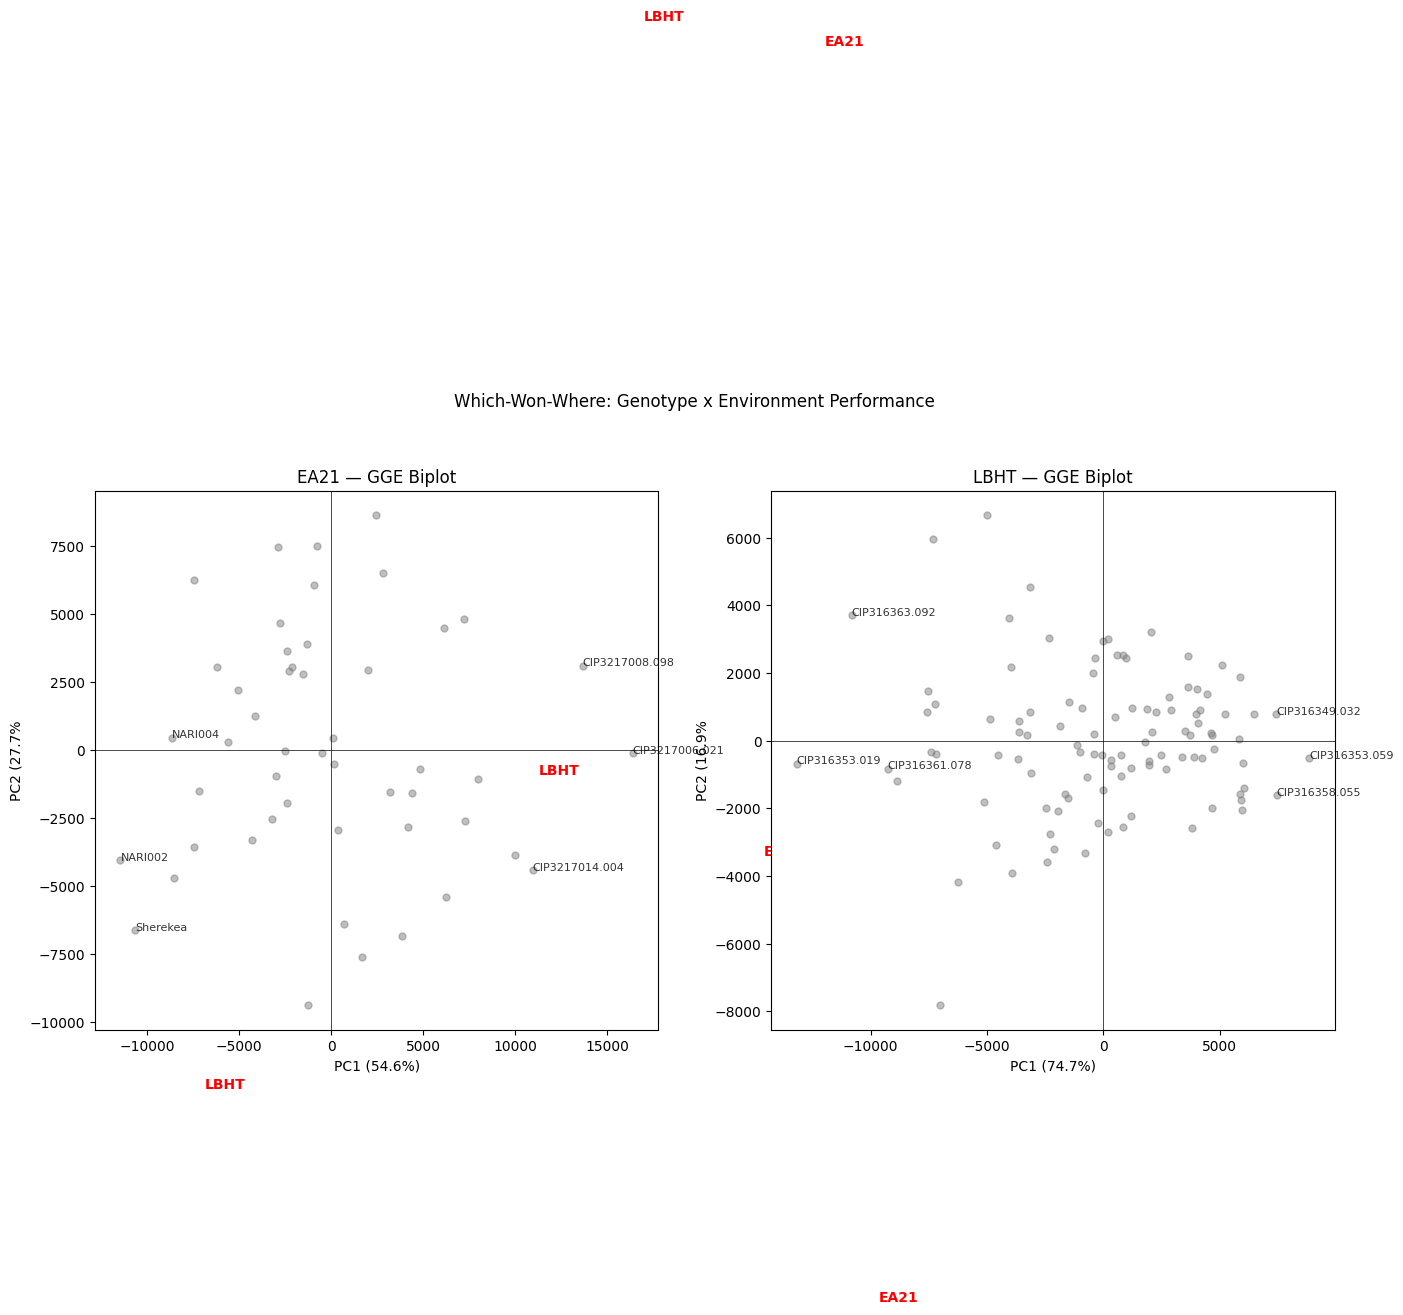

In [ ]:
from numpy.linalg import svd

def build_gge_biplot(population, master, ax_which=None):

    df_pop = master.loc[
        (master["population"] == population) & (master["weight_g_total"].notna())
    ].copy()

    # Genotype x Trial mean yield table
    gxe_table = df_pop.pivot_table(
        index="geno", columns="trial", values="weight_g_total", aggfunc="mean"
    )

    # Keep only genotypes present in ALL trials for this population (GGE requires a complete matrix)
    gxe_complete = gxe_table.dropna()
    print(f"{population}: {gxe_complete.shape[0]} genotypes with complete data across {gxe_complete.shape[1]} trials "
          f"(dropped {gxe_table.shape[0] - gxe_complete.shape[0]} incomplete genotypes)")

    # Center by environment (trial) mean — standard GGE preprocessing (G + GE model, environment-centered)
    env_means = gxe_complete.mean(axis=0)
    gge_matrix = gxe_complete - env_means

    # SVD decomposition
    U, S, Vt = svd(gge_matrix.values, full_matrices=False)

    # Genotype scores (rows) and environment scores (columns) on first two PCs
    geno_scores = U[:, :2] * S[:2]
    env_scores = Vt[:2, :].T * S[:2]

    pc1_var = (S[0]**2 / np.sum(S**2)) * 100
    pc2_var = (S[1]**2 / np.sum(S**2)) * 100

    return gxe_complete, geno_scores, env_scores, pc1_var, pc2_var

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, population in zip(axes, ["EA21", "LBHT"]):
    gxe_complete, geno_scores, env_scores, pc1_var, pc2_var = build_gge_biplot(population, master)

    # Plot genotypes (small grey points)
    ax.scatter(geno_scores[:, 0], geno_scores[:, 1], c="grey", alpha=0.5, s=25, label="Genotypes")

    # Plot environments (trials) as labeled vectors from origin
    for i, trial_name in enumerate(gxe_complete.columns):
        short_name = trial_name.split("-")[1]  # e.g. "MOL", "NJO", "UON"
        ax.annotate("", xy=(env_scores[i, 0], env_scores[i, 1]), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="->", color="red", lw=2))
        ax.text(env_scores[i, 0]*1.1, env_scores[i, 1]*1.1, short_name, color="red", fontweight="bold")

    # Label top 3 and bottom 3 genotypes by PC1 for readability
    pc1_sorted = np.argsort(geno_scores[:, 0])
    for idx in list(pc1_sorted[-3:]) + list(pc1_sorted[:3]):
        ax.annotate(gxe_complete.index[idx], (geno_scores[idx, 0], geno_scores[idx, 1]),
                    fontsize=8, alpha=0.8)

    ax.axhline(0, color="black", lw=0.5)
    ax.axvline(0, color="black", lw=0.5)
    ax.set_xlabel(f"PC1 ({pc1_var:.1f}%)")
    ax.set_ylabel(f"PC2 ({pc2_var:.1f}%")
    ax.set_title(f"{population} — GGE Biplot")

plt.suptitle("Which-Won-Where: Genotype x Environment Performance", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "gge_biplot.png", dpi=300, bbox_inches="tight")
plt.show()

EA21: 49 genotypes with complete data across 3 trials (dropped 15 incomplete genotypes)
LBHT: 105 genotypes with complete data across 3 trials (dropped 22 incomplete genotypes)


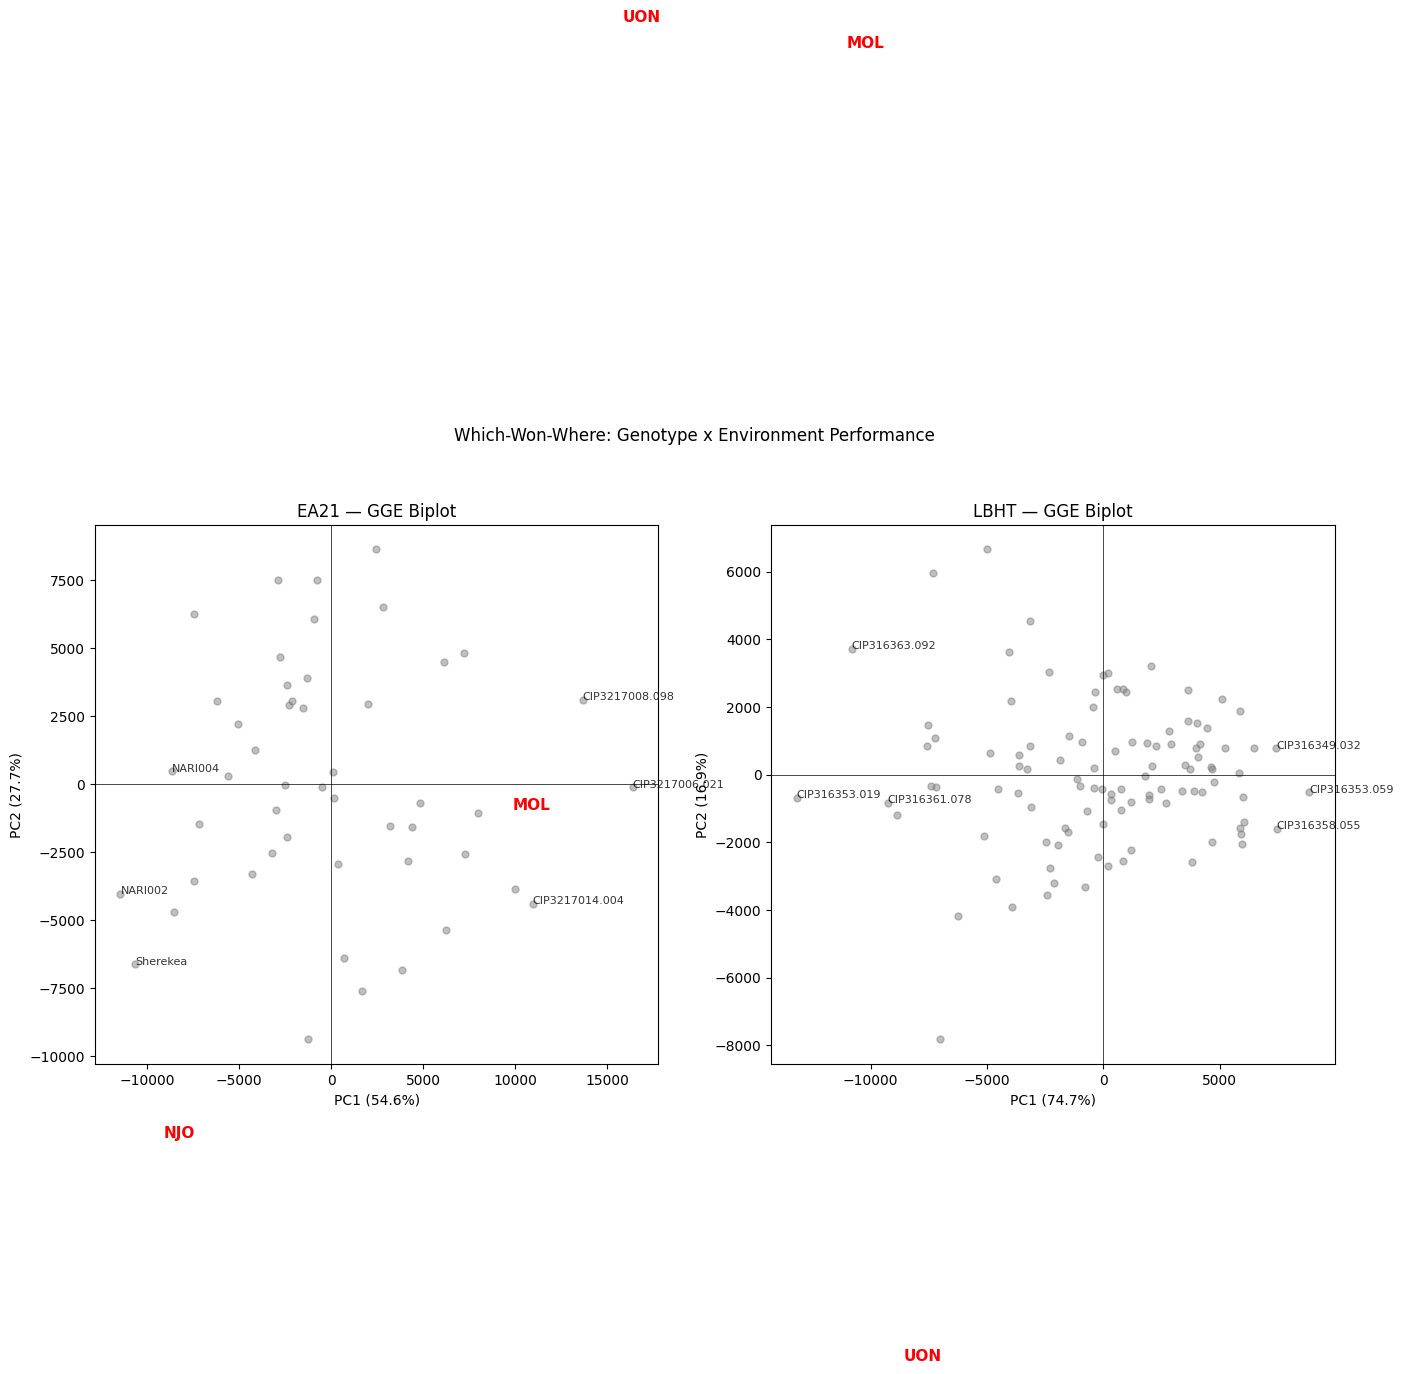

In [ ]:
# ==========================================================
# SECTION 24 (fixed) — GGE Biplot with correct environment labels
# ==========================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, population in zip(axes, ["EA21", "LBHT"]):
    gxe_complete, geno_scores, env_scores, pc1_var, pc2_var = build_gge_biplot(population, master)

    ax.scatter(geno_scores[:, 0], geno_scores[:, 1], c="grey", alpha=0.5, s=25, label="Genotypes")

    for i, trial_name in enumerate(gxe_complete.columns):
        short_name = trial_name[4:7]  # e.g. "MOL", "NJO", "UON" — chars after "KE25"
        ax.annotate("", xy=(env_scores[i, 0], env_scores[i, 1]), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="->", color="red", lw=2))
        ax.text(env_scores[i, 0]*1.15, env_scores[i, 1]*1.15, short_name, color="red", fontweight="bold", fontsize=11)

    pc1_sorted = np.argsort(geno_scores[:, 0])
    for idx in list(pc1_sorted[-3:]) + list(pc1_sorted[:3]):
        ax.annotate(gxe_complete.index[idx], (geno_scores[idx, 0], geno_scores[idx, 1]),
                    fontsize=8, alpha=0.8)

    ax.axhline(0, color="black", lw=0.5)
    ax.axvline(0, color="black", lw=0.5)
    ax.set_xlabel(f"PC1 ({pc1_var:.1f}%)")
    ax.set_ylabel(f"PC2 ({pc2_var:.1f}%)")
    ax.set_title(f"{population} — GGE Biplot")

plt.suptitle("Which-Won-Where: Genotype x Environment Performance", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "gge_biplot.png", dpi=300, bbox_inches="tight")
plt.show()

EA21: 49 genotypes with complete data across 3 trials (dropped 15 incomplete genotypes)
LBHT: 105 genotypes with complete data across 3 trials (dropped 22 incomplete genotypes)


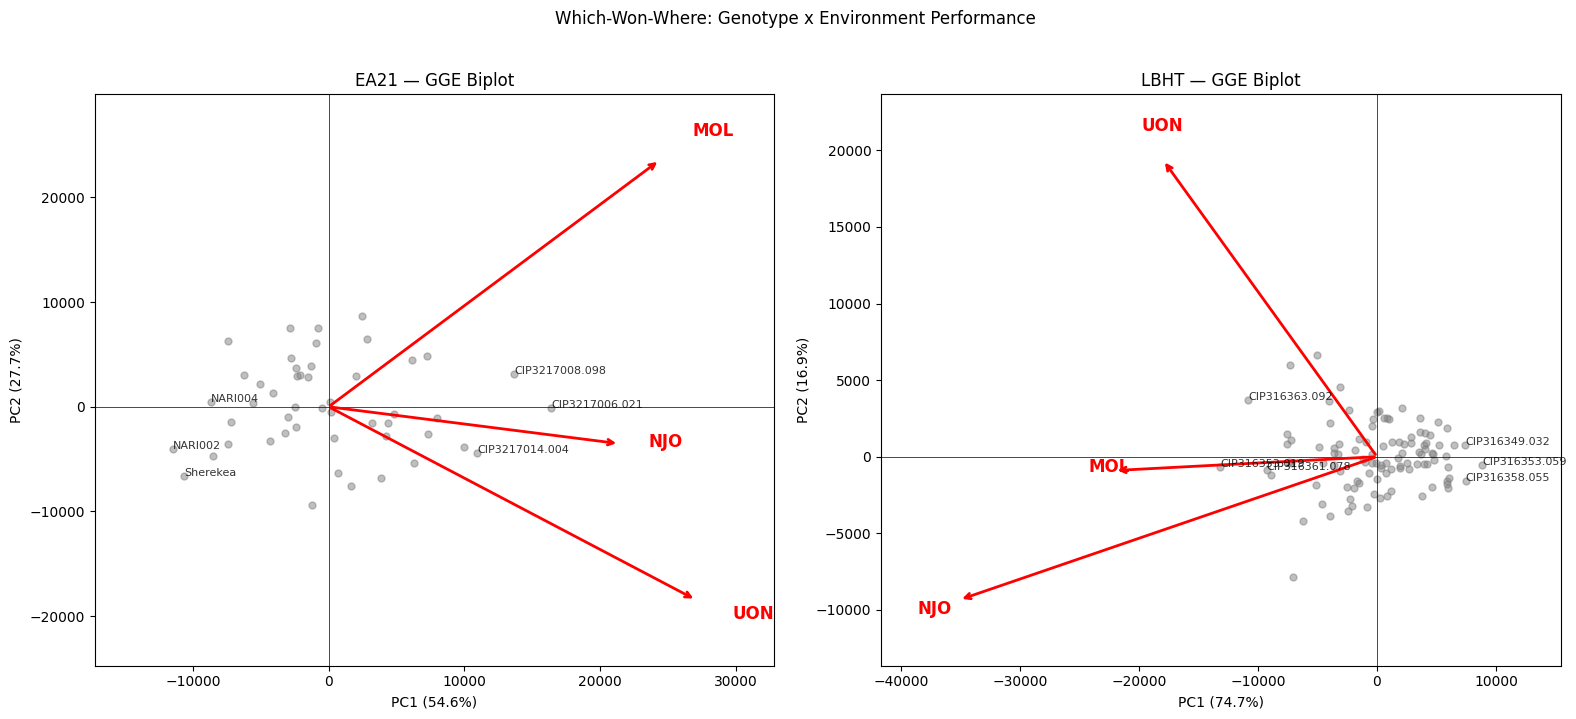

In [ ]:
# ==========================================================
# SECTION 24 (fixed again) — GGE Biplot with proper axis scaling
# ==========================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, population in zip(axes, ["EA21", "LBHT"]):
    gxe_complete, geno_scores, env_scores, pc1_var, pc2_var = build_gge_biplot(population, master)

    ax.scatter(geno_scores[:, 0], geno_scores[:, 1], c="grey", alpha=0.5, s=25, label="Genotypes")

    for i, trial_name in enumerate(gxe_complete.columns):
        short_name = trial_name[4:7]
        ax.annotate("", xy=(env_scores[i, 0], env_scores[i, 1]), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="->", color="red", lw=2))
        ax.text(env_scores[i, 0]*1.1, env_scores[i, 1]*1.1, short_name, color="red", fontweight="bold", fontsize=12)

    pc1_sorted = np.argsort(geno_scores[:, 0])
    for idx in list(pc1_sorted[-3:]) + list(pc1_sorted[:3]):
        ax.annotate(gxe_complete.index[idx], (geno_scores[idx, 0], geno_scores[idx, 1]),
                    fontsize=8, alpha=0.8)

    # --- FIX: expand axis limits to include environment vectors, not just genotype points ---
    all_x = np.concatenate([geno_scores[:, 0], env_scores[:, 0]])
    all_y = np.concatenate([geno_scores[:, 1], env_scores[:, 1]])
    x_pad = (all_x.max() - all_x.min()) * 0.15
    y_pad = (all_y.max() - all_y.min()) * 0.15
    ax.set_xlim(all_x.min() - x_pad, all_x.max() + x_pad)
    ax.set_ylim(all_y.min() - y_pad, all_y.max() + y_pad)

    ax.axhline(0, color="black", lw=0.5)
    ax.axvline(0, color="black", lw=0.5)
    ax.set_xlabel(f"PC1 ({pc1_var:.1f}%)")
    ax.set_ylabel(f"PC2 ({pc2_var:.1f}%)")
    ax.set_title(f"{population} — GGE Biplot")

plt.suptitle("Which-Won-Where: Genotype x Environment Performance", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "gge_biplot.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
!pip install rpy2 --quiet
%load_ext rpy2.ipython

In [ ]:
%%R -i master

NULL


In [ ]:
%%R
install.packages("sommer")
library(sommer)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
also installing the dependencies ‘enhancer’, ‘RcppArmadillo’, ‘RcppProgress’

trying URL 'https://cran.rstudio.com/src/contrib/enhancer_1.1.1.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/RcppArmadillo_15.4.0-1.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/RcppProgress_0.4.2.tar.gz'
trying URL 'https://cran.rstudio.com/src/contrib/sommer_4.4.5.tar.gz'

The downloaded source packages are in
	‘/tmp/RtmpUkKdqV/downloaded_packages’
Loading required package: Matrix
Loading required package: MASS
Loading required package: crayon
Loading required package: enhancer
[]==================================================================[]
[] Package enhancer 1.1.0 (2025-12)                                 []
[] Author: Giovanny Covarrubias-Pazaran  M    (W)                   []
[]==================================================================[]
[]==============================================

In [ ]:
%%R
for (pop in c("EA21", "LBHT")) {
  df_pop <- droplevels(subset(master, population == pop & !is.na(weight_g_total)))

  fit <- mmer(weight_g_total ~ trial,
              random = ~ geno + geno:trial,
              rcov   = ~ units,
              data   = df_pop)

  var_g  <- summary(fit)$varcomp["geno", "VarComp"]
  var_ge <- summary(fit)$varcomp["geno:trial", "VarComp"]
  var_e  <- summary(fit)$varcomp["units", "VarComp"]
  n_env  <- nlevels(df_pop$trial)

  h2 <- var_g / (var_g + var_ge/n_env + var_e/n_env)
  cat(pop, ": Var_G =", var_g, " Var_GE =", var_ge, " Var_E =", var_e, " H2 =", round(h2, 3), "\n")
}

iteration    LogLik     wall    cpu(sec)   restrained
    1      -190.506   18:20:28      0           0
    2      -181.874   18:20:28      0           0
    3      -179.694   18:20:29      1           0
    4      -179.518   18:20:30      2           0
    5      -179.517   18:20:31      3           0
    6      -179.517   18:20:31      3           0
EA21 : Var_G = NA  Var_GE = 9721672  Var_E = 16178827  H2 = NA 
iteration    LogLik     wall    cpu(sec)   restrained
    1      -146.715   18:20:33      1           0
    2      -86.807   18:20:33      1           0
    3      -72.9055   18:20:34      2           0
    4      -71.6864   18:20:35      3           0
    5      -71.6739   18:20:37      5           0
    6      -71.6738   18:20:37      5           0
LBHT : Var_G = NA  Var_GE = 2379532  Var_E = 2836277  H2 = NA 


In [ ]:
%%R
str(master)

'data.frame':	1320 obs. of  121 variables:
 $ plot                     : chr  NA NA NA NA ...
 $ geno                     : chr  "CIP3217004.022" "CIP3177023.046" "CIP3217016.038" "CIP3217016.076" ...
 $ entry                    : chr  "10" "3" "47" "48" ...
 $ row                      : chr  "1" "2" "3" "4" ...
 $ column                   : chr  "1" "1" "1" "1" ...
 $ rep                      : chr  "1" "1" "1" "1" ...
 $ ntp                      : num  20 20 20 20 20 20 20 20 20 20 ...
 $ npe                      : int  20 7 15 17 16 13 20 18 16 18 ...
 $ growth_speed             : num  5 3 5 5 7 5 5 7 3 5 ...
 $ pgh                      : num  2 2 2 2 2 2 2 2 2 2 ...
 $ plant_unif               : num  7 5 5 7 7 5 7 7 7 7 ...
 $ plant_vigor              : num  9 3 5 7 9 5 5 7 3 7 ...
 $ flowering                : num  3 3 0 5 5 3 3 7 0 0 ...
 $ flowering_date           : chr  "2025-07-18 00:00:00" "2024-07-22 00:00:00" NA "2024-07-08 00:00:00" ...
 $ flower_colour            : chr  "

In [ ]:
%%R
head(master)

  plot           geno entry row column rep ntp npe growth_speed pgh plant_unif
0 <NA> CIP3217004.022    10   1      1   1  20  20            5   2          7
1 <NA> CIP3177023.046     3   2      1   1  20   7            3   2          5
2 <NA> CIP3217016.038    47   3      1   1  20  15            5   2          5
3 <NA> CIP3217016.076    48   4      1   1  20  17            5   2          7
4 <NA> CIP3217006.008    20   5      1   1  20  16            7   2          7
5 <NA> CIP3217017.254    52   6      1   1  20  13            5   2          5
  plant_vigor flowering      flowering_date flower_colour overall_impression se
0           9         3 2025-07-18 00:00:00        Purple                  8  7
1           3         3 2024-07-22 00:00:00        White                   4  3
2           5         0                <NA>          <NA>                  5  5
3           7         5 2024-07-08 00:00:00        White                   6  5
4           9         5 2024-07-01 00:00:00    

In [ ]:
%%R
for (pop in c("EA21", "LBHT")) {
  df_pop <- droplevels(subset(master, population == pop & !is.na(weight_g_total)))

  fit <- mmer(weight_g_total ~ trial,
              random = ~ geno + geno:trial,
              rcov   = ~ units,
              data   = df_pop)

  cat("\n===", pop, "===\n")
  print(summary(fit)$varcomp)
}

iteration    LogLik     wall    cpu(sec)   restrained
    1      -190.506   18:24:42      0           0
    2      -181.874   18:24:43      1           0
    3      -179.694   18:24:43      1           0
    4      -179.518   18:24:43      1           0
    5      -179.517   18:24:44      2           0
    6      -179.517   18:24:45      3           0

=== EA21 ===
                                          VarComp VarCompSE    Zratio
geno.weight_g_total-weight_g_total        6921523   2413367  2.867994
geno:trial.weight_g_total-weight_g_total  9721672   2129195  4.565890
units.weight_g_total-weight_g_total      16178827   1228759 13.166803
                                         Constraint
geno.weight_g_total-weight_g_total         Positive
geno:trial.weight_g_total-weight_g_total   Positive
units.weight_g_total-weight_g_total        Positive
iteration    LogLik     wall    cpu(sec)   restrained
    1      -146.715   18:24:46      1           0
    2      -86.807   18:24:47      2    

In [ ]:
%%R
for (pop in c("EA21", "LBHT")) {
  df_pop <- droplevels(subset(master, population == pop & !is.na(weight_g_total)))

  fit <- mmer(weight_g_total ~ trial,
              random = ~ geno + geno:trial,
              rcov   = ~ units,
              data   = df_pop)

  vc <- summary(fit)$varcomp
  var_g  <- vc["geno.weight_g_total-weight_g_total", "VarComp"]
  var_ge <- vc["geno:trial.weight_g_total-weight_g_total", "VarComp"]
  var_e  <- vc["units.weight_g_total-weight_g_total", "VarComp"]

  n_env <- nlevels(df_pop$trial)
  h2 <- var_g / (var_g + var_ge/n_env + var_e/n_env)

  cat(pop, ": Var_G =", var_g,
      " Var_GE =", var_ge,
      " Var_E =", var_e,
      " n_env =", n_env,
      " H2 =", round(h2, 3), "\n")
}

iteration    LogLik     wall    cpu(sec)   restrained
    1      -190.506   18:32:51      0           0
    2      -181.874   18:32:51      0           0
    3      -179.694   18:32:51      0           0
    4      -179.518   18:32:52      1           0
    5      -179.517   18:32:52      1           0
    6      -179.517   18:32:52      1           0
EA21 : Var_G = 6921523  Var_GE = 9721672  Var_E = 16178827  n_env = 0  H2 = 0 
iteration    LogLik     wall    cpu(sec)   restrained
    1      -146.715   18:32:53      0           0
    2      -86.807   18:32:54      1           0
    3      -72.9055   18:32:54      1           0
    4      -71.6864   18:32:54      1           0
    5      -71.6739   18:32:55      2           0
    6      -71.6738   18:32:55      2           0
LBHT : Var_G = 4714566  Var_GE = 2379532  Var_E = 2836277  n_env = 0  H2 = 0 


In [ ]:
%%R
for (pop in c("EA21", "LBHT")) {
  df_pop <- droplevels(subset(master, population == pop & !is.na(weight_g_total)))

  fit <- mmer(weight_g_total ~ trial,
              random = ~ geno + geno:trial,
              rcov   = ~ units,
              data   = df_pop)

  vc <- summary(fit)$varcomp
  var_g  <- vc["geno.weight_g_total-weight_g_total", "VarComp"]
  var_ge <- vc["geno:trial.weight_g_total-weight_g_total", "VarComp"]
  var_e  <- vc["units.weight_g_total-weight_g_total", "VarComp"]

  n_env <- length(unique(df_pop$trial))   # <-- fixed line

  h2 <- var_g / (var_g + var_ge/n_env + var_e/n_env)

  cat(pop, ": Var_G =", var_g,
      " Var_GE =", var_ge,
      " Var_E =", var_e,
      " n_env =", n_env,
      " H2 =", round(h2, 3), "\n")
}

iteration    LogLik     wall    cpu(sec)   restrained
    1      -190.506   18:33:43      0           0
    2      -181.874   18:33:44      1           0
    3      -179.694   18:33:44      1           0
    4      -179.518   18:33:44      1           0
    5      -179.517   18:33:44      1           0
    6      -179.517   18:33:45      2           0
EA21 : Var_G = 6921523  Var_GE = 9721672  Var_E = 16178827  n_env = 3  H2 = 0.445 
iteration    LogLik     wall    cpu(sec)   restrained
    1      -146.715   18:33:46      1           0
    2      -86.807   18:33:47      2           0
    3      -72.9055   18:33:47      2           0
    4      -71.6864   18:33:48      3           0
    5      -71.6739   18:33:48      3           0
    6      -71.6738   18:33:48      3           0
LBHT : Var_G = 4714566  Var_GE = 2379532  Var_E = 2836277  n_env = 3  H2 = 0.731 


In [ ]:
%%R
library(ggplot2)
library(dplyr)
library(scales)

theme_pub <- function() {
  theme_bw(base_size = 14) +
    theme(
      plot.title = element_text(size = 16, face = "bold", hjust = 0.5),
      plot.subtitle = element_text(size = 12, hjust = 0.5),
      axis.title = element_text(face = "bold"),
      axis.text = element_text(colour = "black"),
      legend.position = "top",
      legend.title = element_blank(),
      panel.grid.major.x = element_blank(),
      panel.grid.minor = element_blank(),
      plot.caption = element_text(size = 10)
    )
}

Need help getting started? Try the R Graphics Cookbook:
https://r-graphics.org

Attaching package: ‘ggplot2’

The following object is masked from ‘package:crayon’:

    %+%


Attaching package: ‘dplyr’

The following object is masked from ‘package:MASS’:

    select

The following objects are masked from ‘package:stats’:

    filter, lag

The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



In [ ]:
%%R
var_plot <- data.frame(
  Population = c("EA21","EA21","EA21",
                 "LBHT","LBHT","LBHT"),

  Component = factor(
    c("Genotype",
      "Genotype × Environment",
      "Residual",
      "Genotype",
      "Genotype × Environment",
      "Residual"),
    levels = c("Genotype",
               "Genotype × Environment",
               "Residual")
  ),

  Variance = c(
    6921523,
    9721672,
    16178827,

    4714566,
    2379532,
    2836277
  )
)

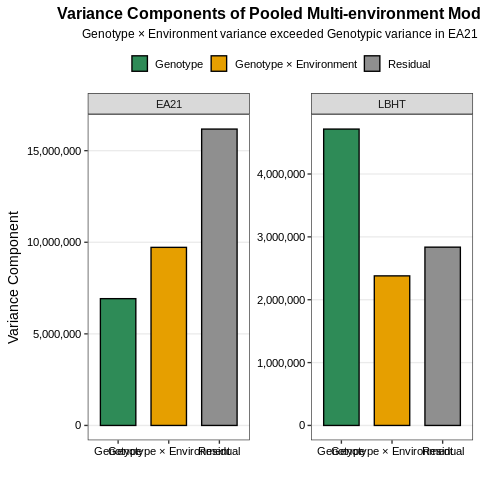

In [ ]:
%%R
gg_var <-
ggplot(
    var_plot,
    aes(
      Component,
      Variance,
      fill = Component
    )
) +

geom_col(
    width = 0.7,
    colour = "black"
) +

facet_wrap(
    ~Population,
    scales = "free_y"
) +

scale_y_continuous(
    labels = comma
) +

labs(

title = "Variance Components of Pooled Multi-environment Models",

subtitle = "Genotype × Environment variance exceeded Genotypic variance in EA21",

x = "",

y = expression("Variance Component")

) +

scale_fill_manual(values=c(

"Genotype"="#2E8B57",

"Genotype × Environment"="#E69F00",

"Residual"="#8F8F8F"

)) +

theme_pub()

gg_var

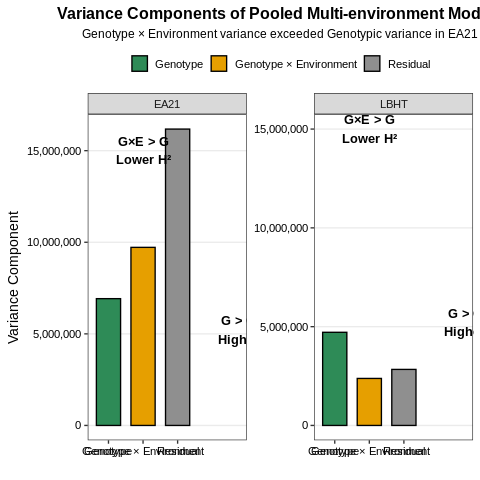

In [ ]:
%%R
gg_var +

annotate(

"text",

x = 2,

y = 15000000,

label = "G×E > G\nLower H²",

size = 4.5,

fontface = "bold"

) +

annotate(

"text",

x = 5,

y = 5200000,

label = "G > G×E\nHigher H²",

size = 4.5,

fontface = "bold"

)

In [ ]:
%%R
ggsave(

filename = "Figure_01_Variance_Components_WPC.png",

plot = gg_var,

width = 10,

height = 6,

dpi = 600,

bg = "white"
)

### Creating a variance table

In [ ]:
%%R
library(tidyverse)

variance_df <- tribble(
  ~Population, ~Component, ~Variance,
  "EA21", "Genotype", 6921523,
  "EA21", "G×E", 9721672,
  "EA21", "Residual", 16178827,
  "LBHT", "Genotype", 4714566,
  "LBHT", "G×E", 2379532,
  "LBHT", "Residual", 2836277
)

variance_df

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ lubridate 1.9.5     ✔ tibble    3.3.1
✔ purrr     1.2.2     ✔ tidyr     1.3.2
✔ readr     2.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ ggplot2::%+%()      masks crayon::%+%()
✖ readr::col_factor() masks scales::col_factor()
✖ purrr::discard()    masks scales::discard()
✖ tidyr::expand()     masks Matrix::expand()
✖ dplyr::filter()     masks stats::filter()
✖ dplyr::lag()        masks stats::lag()
✖ tidyr::pack()       masks Matrix::pack()
✖ dplyr::select()     masks MASS::select()
✖ tidyr::unpack()     masks Matrix::unpack()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
# A tibble: 6 × 3
  Population Component Variance
  <chr>      <chr>        <dbl>
1 EA21       Genotype   6921523
2 EA21       G×E        9721672
3 EA21       Residual  16178827
4 LBHT       Geno

In [ ]:
%%R
variance_pct <-
variance_df %>%
group_by(Population) %>%
mutate(

Total = sum(Variance),

Percent = 100*Variance/Total

)

variance_pct

# A tibble: 6 × 5
# Groups:   Population [2]
  Population Component Variance    Total Percent
  <chr>      <chr>        <dbl>    <dbl>   <dbl>
1 EA21       Genotype   6921523 32822022    21.1
2 EA21       G×E        9721672 32822022    29.6
3 EA21       Residual  16178827 32822022    49.3
4 LBHT       Genotype   4714566  9930375    47.5
5 LBHT       G×E        2379532  9930375    24.0
6 LBHT       Residual   2836277  9930375    28.6


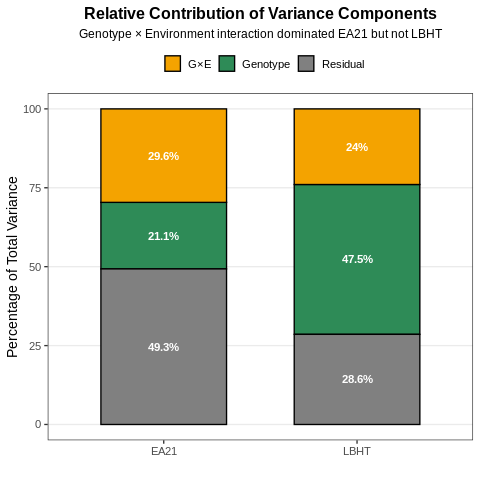

In [ ]:
%%R
library(ggplot2)

ggplot(
    variance_pct,
    aes(
        Population,
        Percent,
        fill = Component
    )
)+

geom_col(
    width = 0.65,
    colour="black"
)+

geom_text(
    aes(label=paste0(round(Percent,1),"%")),
    position=position_stack(vjust=0.5),
    colour="white",
    fontface="bold",
    size=4
)+

scale_fill_manual(values=c(

"Genotype"="#2E8B57",

"G×E"="#F4A300",

"Residual"="#808080"

))+

labs(

title="Relative Contribution of Variance Components",

subtitle="Genotype × Environment interaction dominated EA21 but not LBHT",

x="",

y="Percentage of Total Variance",

fill=""

)+

theme_bw(base_size=14)+

theme(

plot.title=element_text(face="bold",size=16,hjust=0.5),

plot.subtitle=element_text(size=12,hjust=0.5),

legend.position="top",

panel.grid.major.x=element_blank(),

panel.grid.minor=element_blank()

)

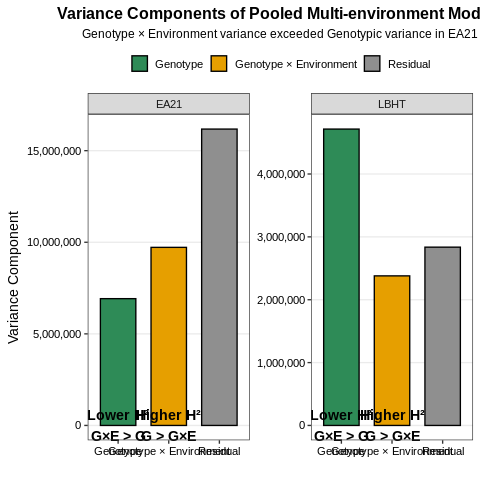

In [ ]:
%%R
gg_var +
annotate(
"text",
x=1,
y=97,
label="Lower H²\nG×E > G",
fontface="bold",
size=5
)+

annotate(
"text",
x=2,
y=97,
label="Higher H²\nG > G×E",
fontface="bold",
size=5
)

In [ ]:
%%R
ggsave(
"Figure01_VarianceComponents_WPC.png",
width=7,
height=6,
dpi=600,
bg="white"
)

ggsave(
"Figure01_VarianceComponents_WPC.pdf",
width=7,
height=6
)

In [ ]:
%%R
install.packages("patchwork")   # Run once if you don't already have it

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
trying URL 'https://cran.rstudio.com/src/contrib/patchwork_1.3.2.tar.gz'
Content type 'application/x-gzip' length 3322521 bytes (3.2 MB)
downloaded 3.2 MB


The downloaded source packages are in
	‘/tmp/RtmpUkKdqV/downloaded_packages’


In [ ]:
%%R
library(tidyverse)
library(scales)
library(patchwork)


Attaching package: ‘patchwork’

The following object is masked from ‘package:MASS’:

    area



In [ ]:
%%R
variance_df <- tribble(
  ~Population, ~Component, ~Variance,
  "EA21","Genotype",6921523,
  "EA21","G×E",9721672,
  "EA21","Residual",16178827,
  "LBHT","Genotype",4714566,
  "LBHT","G×E",2379532,
  "LBHT","Residual",2836277
)

variance_df <- variance_df %>%
  mutate(
    Component = factor(
      Component,
      levels = c("Genotype","G×E","Residual")
    )
  )

variance_pct <- variance_df %>%
  group_by(Population) %>%
  mutate(
    Total = sum(Variance),
    Percent = 100 * Variance / Total
  )

In [ ]:
%%R
theme_poster <- function(){

theme_classic(base_size = 15)+

theme(

plot.title = element_text(
face="bold",
size=17,
hjust=.5
),

plot.subtitle = element_text(
size=12,
hjust=.5
),

legend.position="top",

legend.title=element_blank(),

axis.title=element_text(face="bold"),

strip.text=element_text(face="bold",size=14)

)

}

In [ ]:
# Absolute Variance
%%R
p1 <-

ggplot(
variance_df,
aes(
Component,
Variance/1e6,
fill=Component
)
)+

geom_col(
width=.65,
colour="black"
)+

facet_wrap(~Population)+

geom_text(
aes(label=round(Variance/1e6,1)),
vjust=-0.4,
fontface="bold",
size=4
)+

scale_fill_manual(values=c(

"Genotype"="#1B9E77",

"G×E"="#D95F02",

"Residual"="#7570B3"

))+

labs(

title="A. Absolute Variance Components",

x="",

y="Variance (×10⁶)"

)+

theme_poster()

In [ ]:
# Relative Contribution
%%R
p2 <-

ggplot(

variance_pct,

aes(

Population,

Percent,

fill=Component

)

)+

geom_col(
width=.65,
colour="black"
)+

geom_text(

aes(

label=paste0(round(Percent,1),"%")

),

position=position_stack(.5),

colour="white",

fontface="bold",

size=4

)+

scale_fill_manual(values=c(

"Genotype"="#1B9E77",

"G×E"="#D95F02",

"Residual"="#7570B3"

))+

labs(

title="B. Relative Contribution",

x="",

y="Percent of Total Variance"

)+

theme_poster()

### Combining the panels

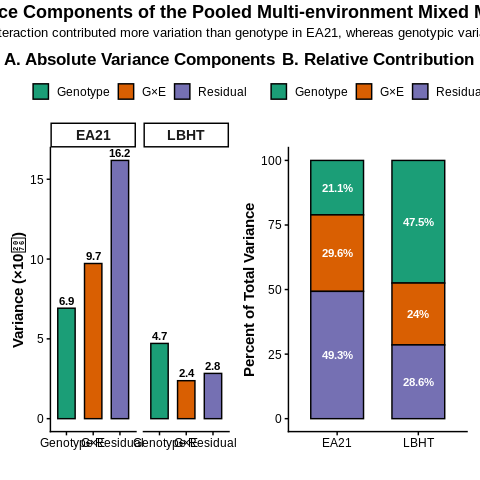

In [ ]:
%%R
figure1 <-

p1 + p2 +

plot_annotation(

title="Variance Components of the Pooled Multi-environment Mixed Models",

subtitle="Genotype × Environment interaction contributed more variation than genotype in EA21, whereas genotypic variance predominated in LBHT.",

theme=theme(

plot.title=element_text(
size=18,
face="bold",
hjust=.5
),

plot.subtitle=element_text(
size=13,
hjust=.5
)

)

)

figure1

In [ ]:
%%R
ggsave(

filename="Figure1_VarianceComponents_WPC.png",

plot=figure1,

width=12,

height=6,

dpi=600,

bg="white"
)

ggsave(

filename="Figure1_VarianceComponents_WPC.pdf",

plot=figure1,

width=12,

height=6
)

In addition: Warning message:
In grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y,  :
  conversion failure on 'Variance (×10⁶)' in 'mbcsToSbcs': for ⁶ (U+2076)


In [117]:
%%R

publication_variance <- data.frame(

Population = c("EA21","LBHT"),

Var_G = c(
6921523,
4714566
),

Var_GE = c(
9721672,
2379532
),

Var_E = c(
16178827,
2836277
),

Environments = c(
3,
3
),

H2 = c(
0.445,
0.730
)

)

publication_variance

  Population   Var_G  Var_GE    Var_E Environments    H2
1       EA21 6921523 9721672 16178827            3 0.445
2       LBHT 4714566 2379532  2836277            3 0.730


In [123]:
import os

print(os.getcwd())

/content


In [124]:
os.listdir()

['.config',
 'Figure01_VarianceComponents_WPC.pdf',
 'Figure1_VarianceComponents_WPC.png',
 'Figure_01_Variance_Components_WPC.png',
 'drive',
 'Figure01_VarianceComponents_WPC.png',
 'Figure1_VarianceComponents_WPC.pdf',
 'sample_data']

In [130]:
%%R -i TABLES_DIR_STR

write.csv(
  publication_variance,
  file = file.path(TABLES_DIR_STR, "publication_variance_components.csv"),
  row.names = FALSE
)

In [131]:
%%R -i OUTPUT_DIR_STR

write.csv(
  publication_variance,
  file=file.path(OUTPUT_DIR_STR,
"publication_variance_components.csv"),
  row.names=FALSE
)

In [ ]:
%%R

variance_df <- read.csv(

file.path(
RESULTS_DIR,
"publication_variance_components.csv"
)

)

variance_df

In [132]:
import os

# Verify that the CSV file was created
csv_file_path = os.path.join(TABLES_DIR_STR, "publication_variance_components.csv")

if os.path.exists(csv_file_path):
    print(f"File '{csv_file_path}' successfully created.")
else:
    print(f"Error: File '{csv_file_path}' was not found.")


File '/content/drive/MyDrive/Potato_CET_Project/outputs/tables/publication_variance_components.csv' successfully created.


In [133]:
%%R -i TABLES_DIR_STR

# Read the saved CSV back into an R dataframe for verification
variance_df_from_csv <- read.csv(
  file.path(TABLES_DIR_STR, "publication_variance_components.csv")
)

print("Dataframe loaded from CSV:")
print(variance_df_from_csv)

[1] "Dataframe loaded from CSV:"
  Population   Var_G  Var_GE    Var_E Environments    H2
1       EA21 6921523 9721672 16178827            3 0.445
2       LBHT 4714566 2379532  2836277            3 0.730
